In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = '/content/drive/MyDrive/(11.02.2025) Квартиры 2014 кольцо.csv'
df = pd.read_csv(file_path)

**Загрузка и очистка данных**

In [ ]:
# Проверка загрузки данных
df.head()

,Идентификатор,Комнатность,Новостройка,Метро.Район,Время.до.метро,Улица,Дом,Этаж,Этажность,Площадь.общая,Площадь.жилая,Площадь.кухни,Ценавруб.,Ценавдолл.,Ценавевро,Источник.получения,Дата.объявления,Контакты,На.сайте,Описание
0,24016418,1,Нет,Киевская,15.0,Сколковское ш.,36,4,9.0,21.0,16.0,4.0,3500000.0,99488,73466,Дом Сервис+,23.01.2014 5:20:30,"Тел.: 89150801223, http://www.7829980.ru, mail...",NaN,"Квартира 1-комн., общ.пл.-21, жил.пл.-16, кухн..."
1,23454997,1,Нет,Киевская,10.0,Матвеевская,26,5,5.0,31.0,18.0,6.0,4700000.0,133598,98654,Азбука Жилья,19.10.2013 5:05:10,"Тел.: +7 (495) 795-0569, http://http://www.azb...",NaN,"Квартира 1-комн., общ.пл.-31, жил.пл.-18, кухн..."
2,23697825,1,Нет,Марксистская,10.0,Бронницкая,4,5,5.0,32.0,18.0,7.0,5000000.0,145942,107770,ИНКОМ-Недвижимость,13.11.2013 12:20:37,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 1-комн., общ.пл.-32.00, жил.пл.-18.00..."
3,23712199,1,Нет,Марксистская,5.0,Нижегородская,53,1,9.0,36.0,14.4,8.0,5350000.0,156158,115314,ИНКОМ-Недвижимость,16.11.2013 12:20:46,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 1-комн., общ.пл.-36.00, жил.пл.-14.40..."
4,23701679,2,Нет,Таганская,10.0,Карачаровская 1-я,17,5,5.0,41.0,25.0,6.0,5350000.0,156158,115314,ИНКОМ-Недвижимость,14.11.2013 12:20:55,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 2-комн., общ.пл.-41.00, жил.пл.-25.00..."


In [4]:
# Создаем копию исходного DataFrame для очистки
df_cleaned = df.copy()

# Список столбцов для удаления
columns_to_drop = [
    'Идентификатор', 'Улица', 'Дом', 'Источник.получения',
    'Дата.объявления', 'Контакты', 'На.сайте', 'Описание',
    'Ценавдолл.', 'Ценавевро'
]

# Создаем новый DataFrame без указанных столбцов
df_cleaned = df_cleaned.drop(columns=columns_to_drop)

# Проверяем результат
df_cleaned.head()

,Комнатность,Новостройка,Метро.Район,Время.до.метро,Этаж,Этажность,Площадь.общая,Площадь.жилая,Площадь.кухни,Ценавруб.
0,1,Нет,Киевская,15.0,4,9.0,21.0,16.0,4.0,3500000.0
1,1,Нет,Киевская,10.0,5,5.0,31.0,18.0,6.0,4700000.0
2,1,Нет,Марксистская,10.0,5,5.0,32.0,18.0,7.0,5000000.0
3,1,Нет,Марксистская,5.0,1,9.0,36.0,14.4,8.0,5350000.0
4,2,Нет,Таганская,10.0,5,5.0,41.0,25.0,6.0,5350000.0


In [5]:
# Проверка типов данных и общей информации о DataFrame
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2002 entries, 0 to 2001
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Комнатность     2002 non-null   int64  
 1   Новостройка     2002 non-null   object 
 2   Метро.Район     2002 non-null   object 
 3   Время.до.метро  1801 non-null   float64
 4   Этаж            1995 non-null   object 
 5   Этажность       1971 non-null   float64
 6   Площадь.общая   1999 non-null   float64
 7   Площадь.жилая   1843 non-null   float64
 8   Площадь.кухни   891 non-null    float64
 9   Ценавруб.       2002 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 156.5+ KB


In [6]:
# Преобразуем столбец "Этаж" в строковый тип (если это еще не сделано)
df_cleaned['Этаж'] = df_cleaned['Этаж'].astype(str)

# Создаем множество уникальных символов для каждого значения в столбце "Этаж"
unique_chars = df_cleaned['Этаж'].apply(lambda x: set(str(x)))

# Выводим уникальные символы
print("Уникальные символы в столбце 'Этаж':")
print(unique_chars)

# Находим строки, которые содержат нечисловые символы
non_numeric_values = df_cleaned[df_cleaned['Этаж'].apply(lambda x: not x.isnumeric())]
print("\nСтроки с нечисловыми значениями в столбце 'Этаж':")
print(non_numeric_values['Этаж'])

Уникальные символы в столбце 'Этаж':
0          {4}
1          {5}
2          {5}
3          {1}
4          {5}
         ...  
1997    {2, 1}
1998       {7}
1999    {3, 4}
2000    {3, 4}
2001       {1}
Name: Этаж, Length: 2002, dtype: object

Строки с нечисловыми значениями в столбце 'Этаж':
23        ?
142       ?
560       ?
616     nan
808     nan
960       ?
1397    nan
1441    nan
1695    nan
1800    nan
1904    nan
Name: Этаж, dtype: object


In [7]:
# Заменяем лишние значения на numpy.nan
df_cleaned['Этаж'] = df_cleaned['Этаж'].replace({'?': np.nan, 'nan': np.nan})

# Преобразуем столбец в числовой тип
df_cleaned['Этаж'] = pd.to_numeric(df_cleaned['Этаж'], errors='coerce')

In [8]:
print("Информация о типах данных всех полей:")
df_cleaned.info()

Информация о типах данных всех полей:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2002 entries, 0 to 2001
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Комнатность     2002 non-null   int64  
 1   Новостройка     2002 non-null   object 
 2   Метро.Район     2002 non-null   object 
 3   Время.до.метро  1801 non-null   float64
 4   Этаж            1991 non-null   float64
 5   Этажность       1971 non-null   float64
 6   Площадь.общая   1999 non-null   float64
 7   Площадь.жилая   1843 non-null   float64
 8   Площадь.кухни   891 non-null    float64
 9   Ценавруб.       2002 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 156.5+ KB


In [9]:
print("Количество пропущенных значений в столбце 'Этаж':", df_cleaned['Этаж'].isnull().sum())

# Если пропущенных значений нет, преобразуем в int64
if df_cleaned['Этаж'].isnull().sum() == 0:
    df_cleaned['Этаж'] = df_cleaned['Этаж'].astype(int)
    print("\nТип данных столбца 'Этаж' после преобразования:", df_cleaned['Этаж'].dtype)
else:
    print("\nВ столбце 'Этаж' есть пропущенные значения. Удалите или заполните их перед преобразованием.")

Количество пропущенных значений в столбце 'Этаж': 11

В столбце 'Этаж' есть пропущенные значения. Удалите или заполните их перед преобразованием.


In [10]:
# Удаление дубликатов
df_cleaned = df_cleaned.drop_duplicates()

# Проверка результата
print("Количество строк после удаления дубликатов:", len(df_cleaned))

Количество строк после удаления дубликатов: 1599


**Работа с пропусками**

In [11]:
!pip install missingno

Количество пропусков в каждом столбце:
Комнатность         0
Новостройка         0
Метро.Район         0
Время.до.метро    201
Этаж               11
Этажность          31
Площадь.общая       3
Площадь.жилая     159
Площадь.кухни     714
Ценавруб.           0
dtype: int64


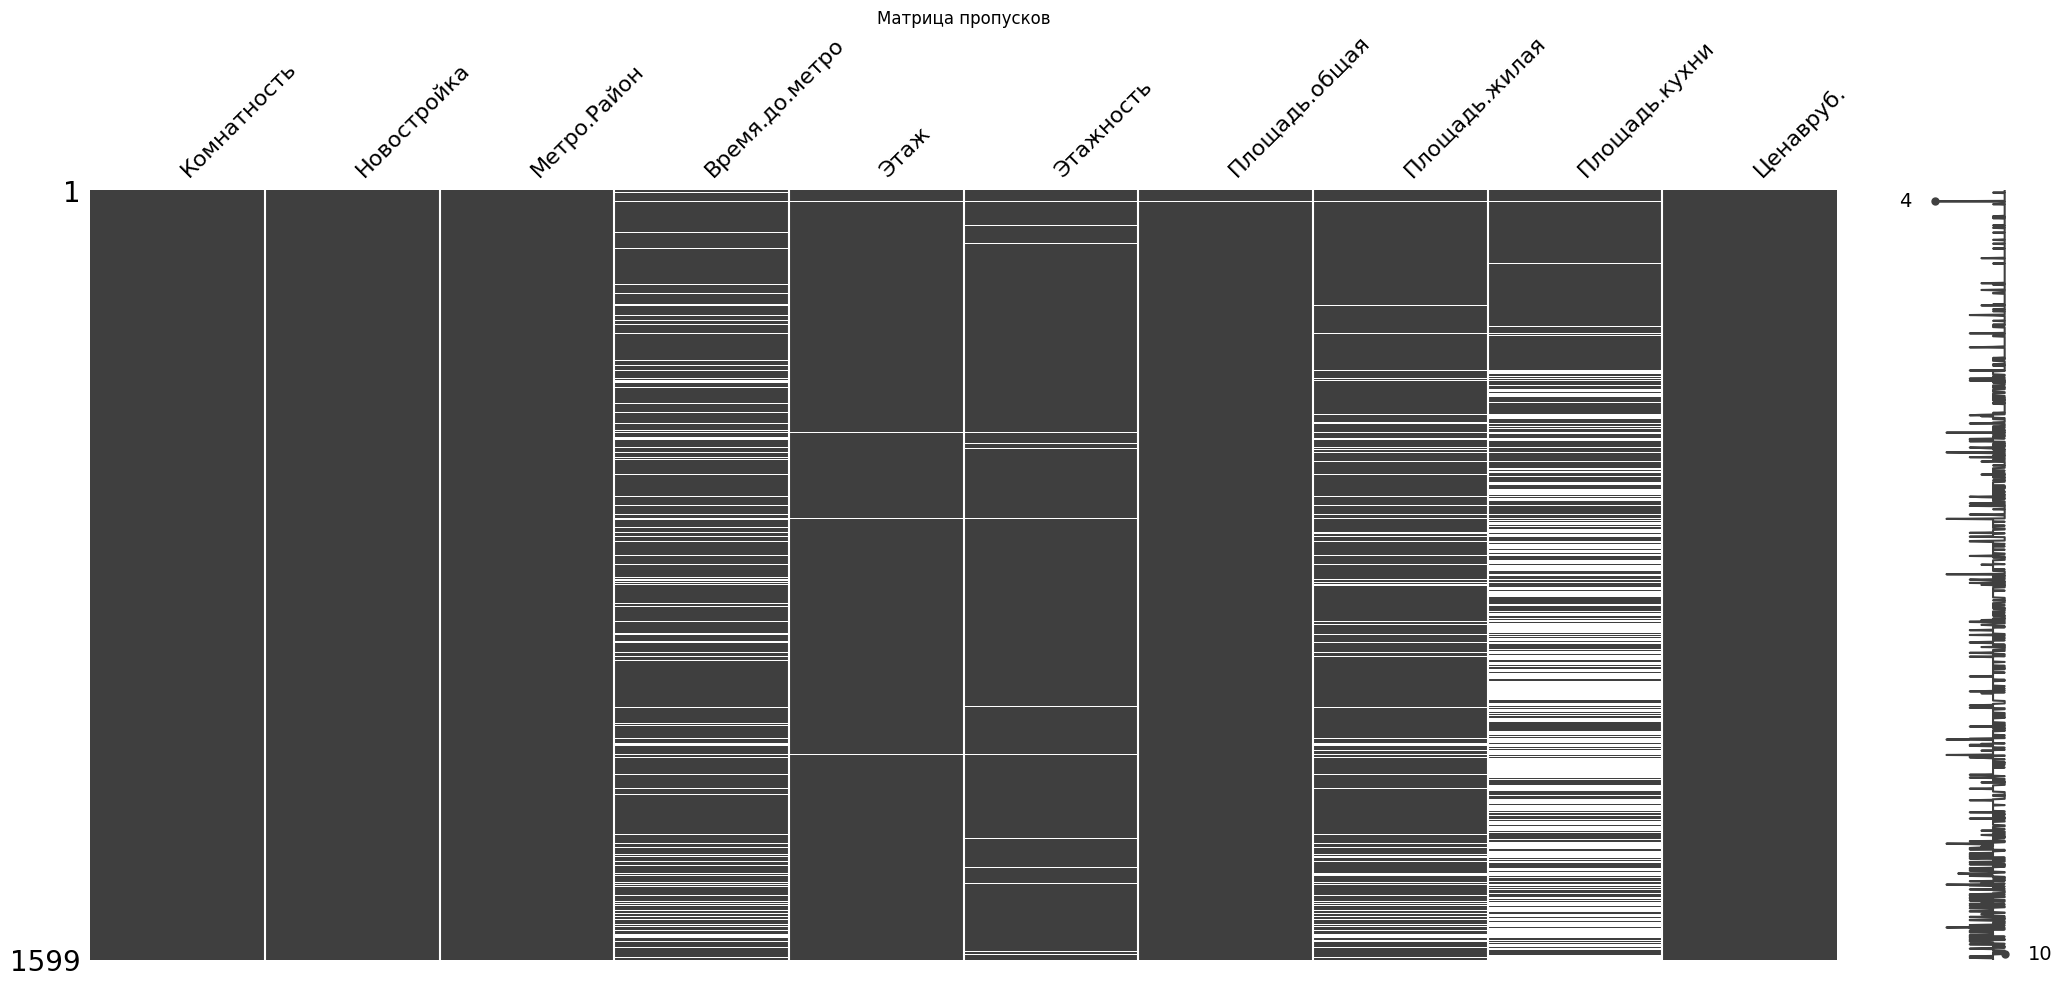

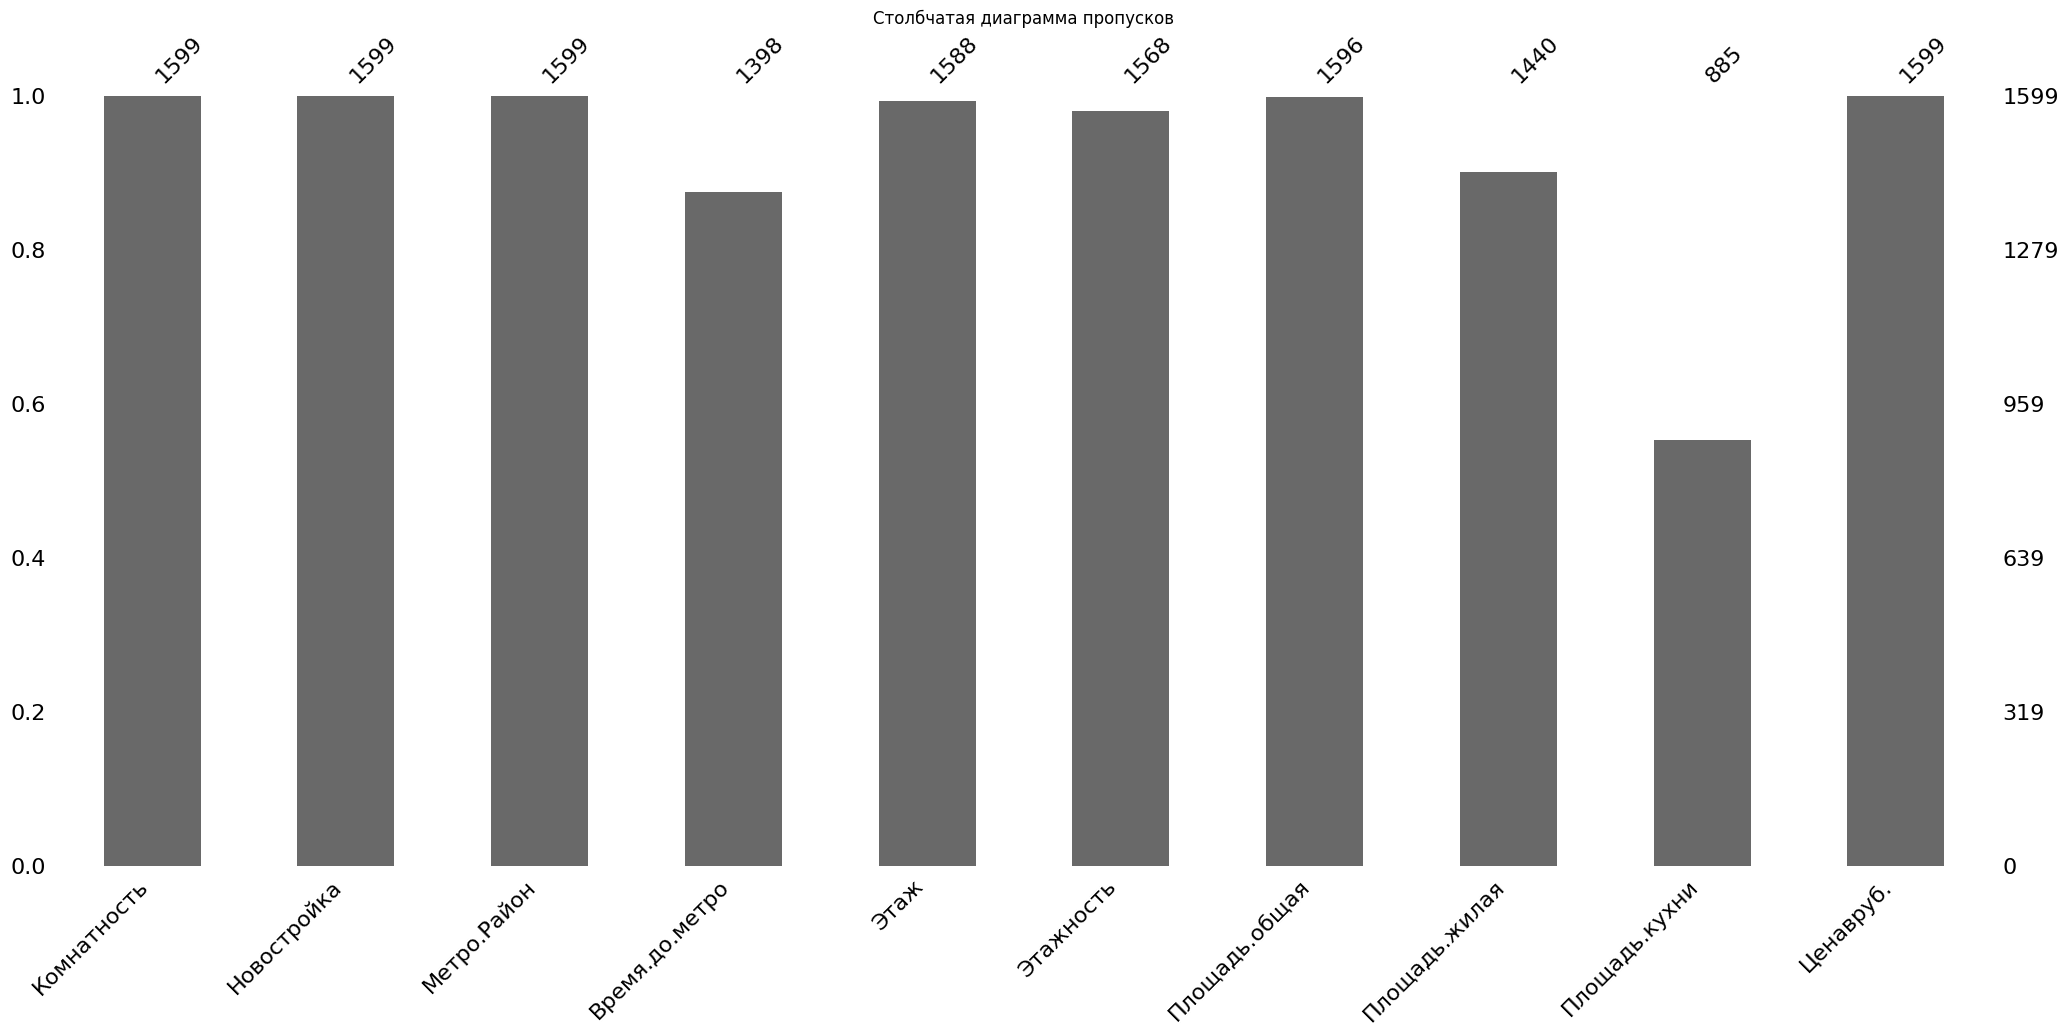

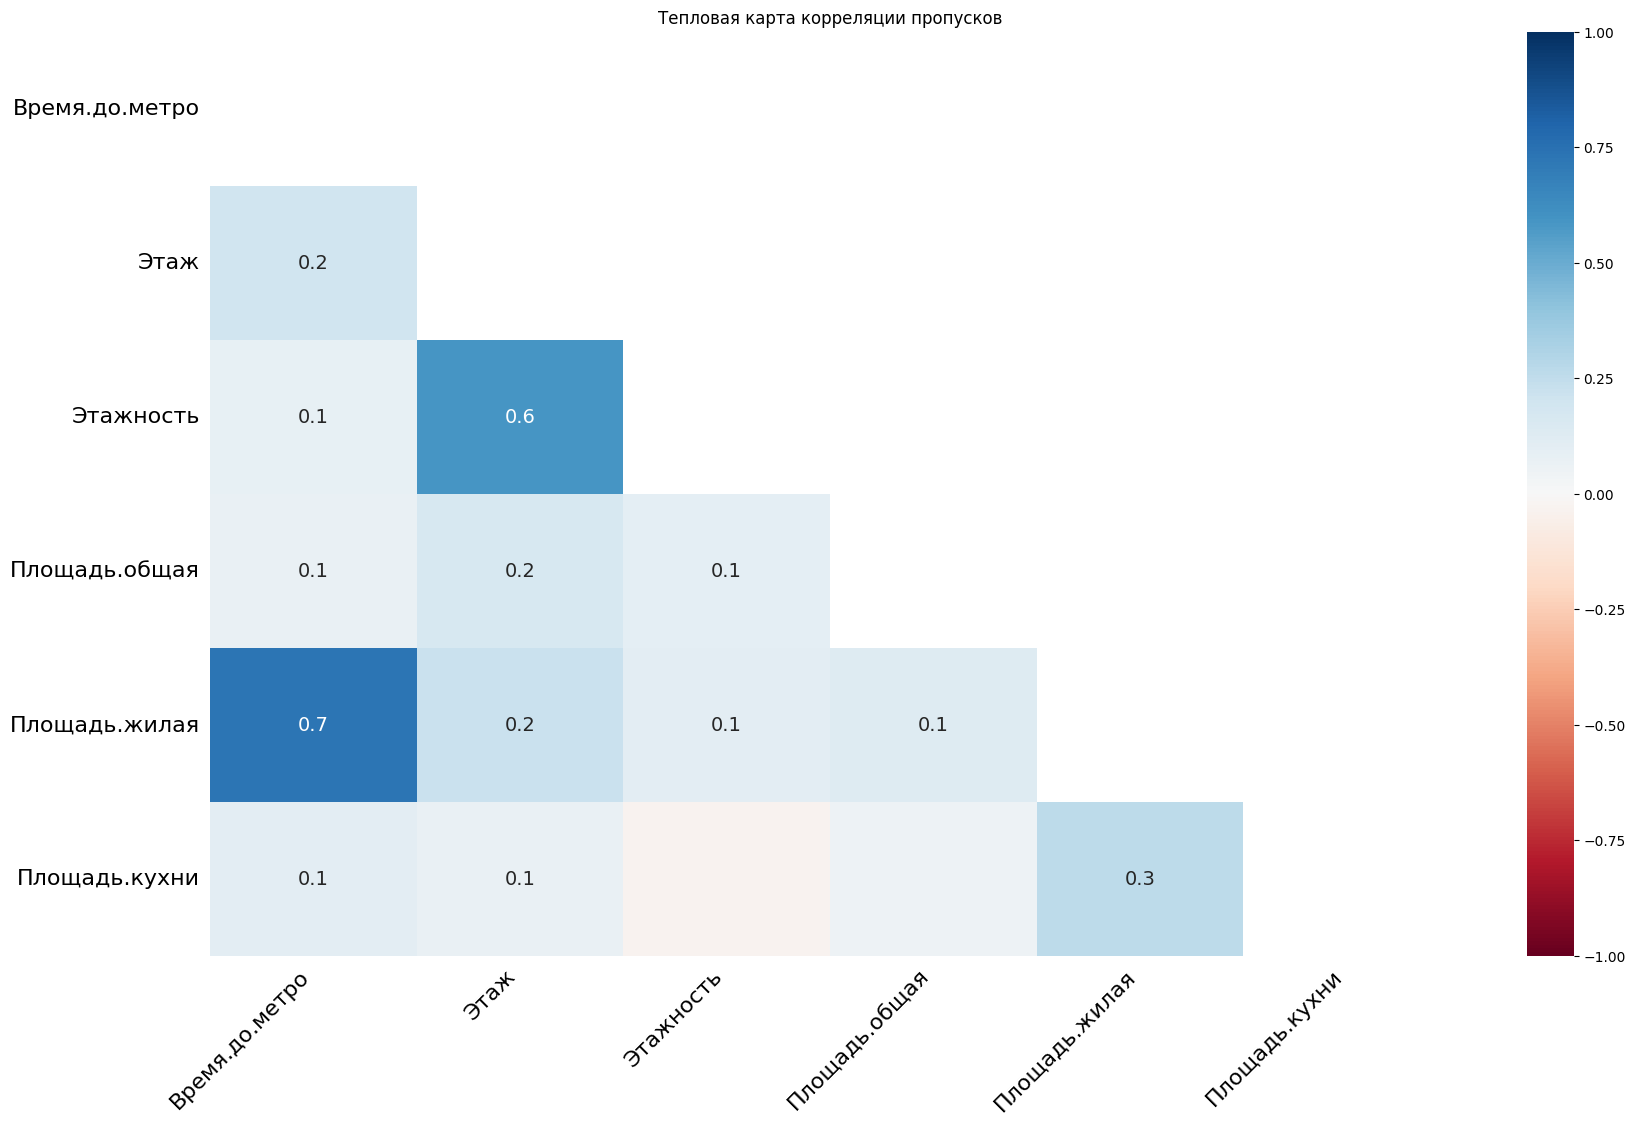

In [12]:
# Подсчет пропусков в каждом столбце
missing_values = df_cleaned.isna().sum()
print("Количество пропусков в каждом столбце:")
print(missing_values)

# Визуализация пропусков с помощью missingno
import missingno as msno
import matplotlib.pyplot as plt

# Матрица пропусков
msno.matrix(df_cleaned)
plt.title("Матрица пропусков")
plt.show()

# Столбчатая диаграмма пропусков
msno.bar(df_cleaned)
plt.title("Столбчатая диаграмма пропусков")
plt.show()

# Тепловая карта корреляции пропусков
msno.heatmap(df_cleaned)
plt.title("Тепловая карта корреляции пропусков")
plt.show()

Поля 'Площадь.общая' и
'Площадь.жилая' сильно коррелируют
между собой. Площадь жилая содержит больше пропусков, чем площадь общая, удалим его.

In [13]:
# Удаляем столбец 'Площадь.жилая', так как в нем больше пропусков
df_cleaned = df_cleaned.drop(columns=['Площадь.жилая'])

# Проверяем результат
print("Столбцы после удаления 'Площадь.жилая':")
print(df_cleaned.columns)

Столбцы после удаления 'Площадь.жилая':
Index(['Комнатность', 'Новостройка', 'Метро.Район', 'Время.до.метро', 'Этаж',
       'Этажность', 'Площадь.общая', 'Площадь.кухни', 'Ценавруб.'],
      dtype='object')


In [14]:
# Вычисляем медианное значение для столбца 'Время.до.метро'
median_time_to_metro = df_cleaned['Время.до.метро'].median()
print("Медианное значение для 'Время.до.метро':", median_time_to_metro)

# Заполняем пропуски медианным значением
df_cleaned['Время.до.метро'] = df_cleaned['Время.до.метро'].fillna(median_time_to_metro)

# Проверяем результат
print("Количество пропусков в 'Время.до.метро' после заполнения:",
      df_cleaned['Время.до.метро'].isna().sum())

Медианное значение для 'Время.до.метро': 10.0
Количество пропусков в 'Время.до.метро' после заполнения: 0


In [15]:
# Вычисляем средние значения площади кухни для каждой группы по количеству комнат
mean_kitchen_by_rooms = df_cleaned.groupby('Комнатность')['Площадь.кухни'].transform('mean')

# Заполняем пропуски в 'Площадь.кухни' средними значениями по количеству комнат
df_cleaned['Площадь.кухни'] = df_cleaned['Площадь.кухни'].fillna(mean_kitchen_by_rooms)

# Проверяем результат
print("Количество пропусков в 'Площадь.кухни' после заполнения:",
      df_cleaned['Площадь.кухни'].isna().sum())

Количество пропусков в 'Площадь.кухни' после заполнения: 6


In [16]:
print("Количество пропусков в каждом столбце:")
print(df_cleaned.isna().sum())

Количество пропусков в каждом столбце:
Комнатность        0
Новостройка        0
Метро.Район        0
Время.до.метро     0
Этаж              11
Этажность         31
Площадь.общая      3
Площадь.кухни      6
Ценавруб.          0
dtype: int64


In [17]:
# Удаляем строки, в которых есть пропуски
df_cleaned = df_cleaned.dropna()

# Проверяем результат
print("\nКоличество пропусков после удаления строк:")
print(df_cleaned.isna().sum())


Количество пропусков после удаления строк:
Комнатность       0
Новостройка       0
Метро.Район       0
Время.до.метро    0
Этаж              0
Этажность         0
Площадь.общая     0
Площадь.кухни     0
Ценавруб.         0
dtype: int64


**Работа с выбросами**

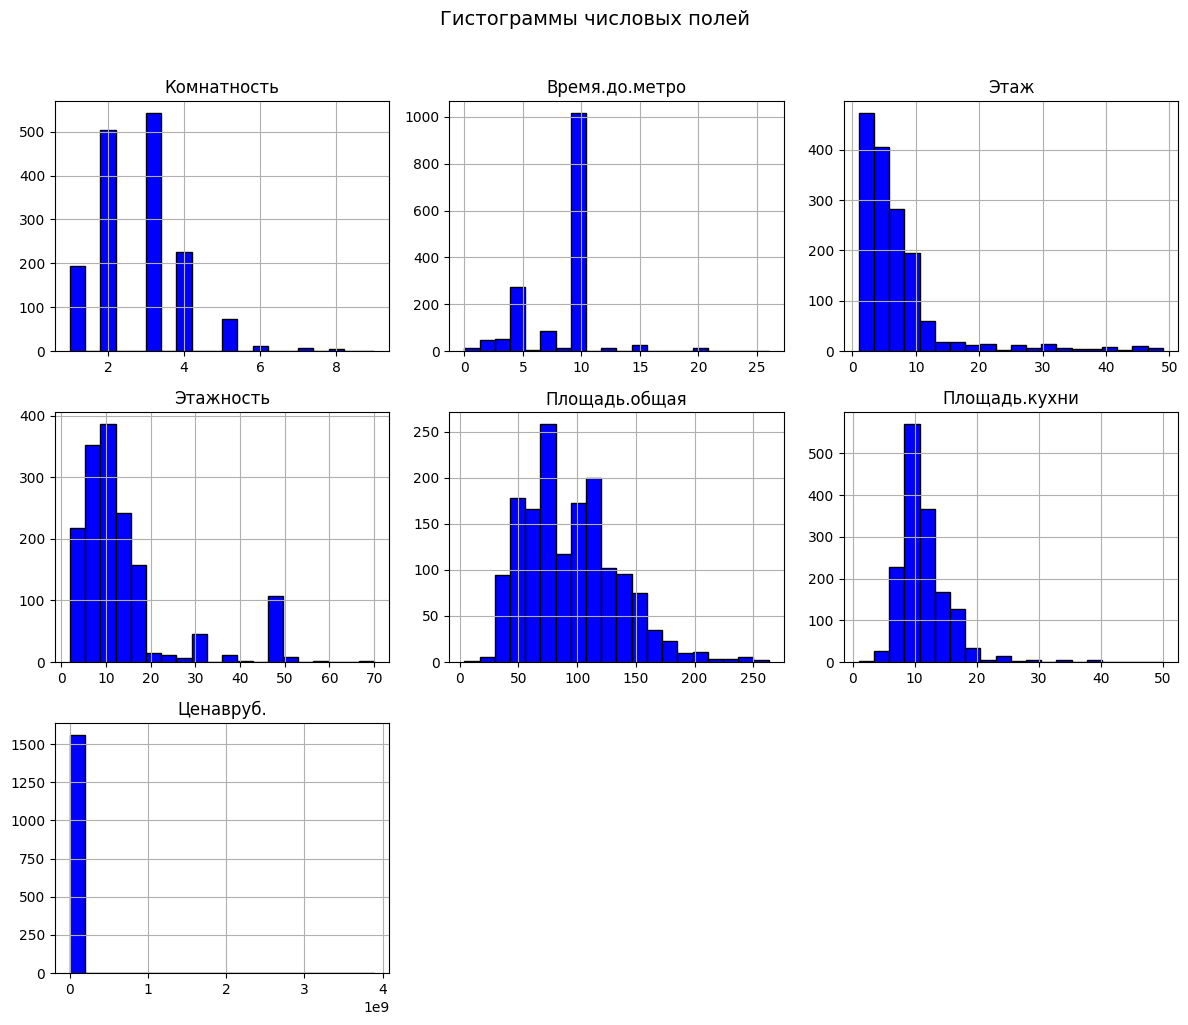

In [18]:
import matplotlib.pyplot as plt

# Построение гистограмм для всех числовых полей
df_cleaned.hist(figsize=(12, 10), bins=20, color='blue', edgecolor='black')
plt.suptitle("Гистограммы числовых полей", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Поле ‘Ценавруб.’ распределено
очень неравномерно. Построим ящик с усами
(boxplot) для этого поля.

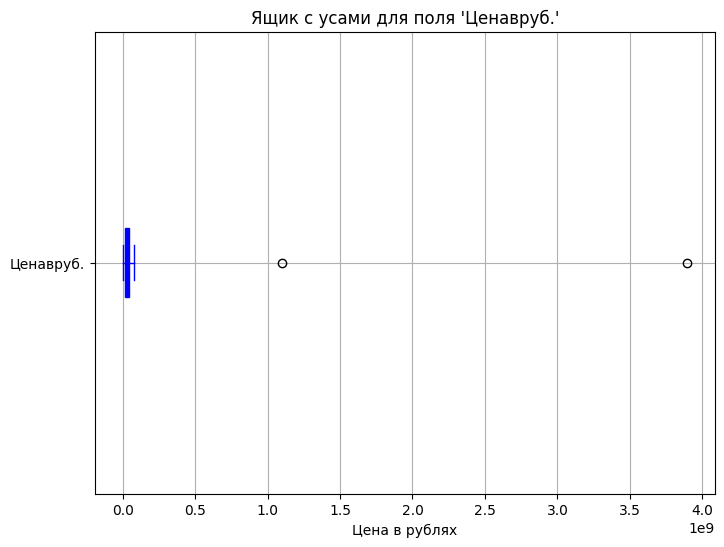

In [19]:
# Построение boxplot для поля 'Ценавруб.'
plt.figure(figsize=(8, 6))  # Задаем размер графика
df_cleaned.boxplot(column='Ценавруб.', vert=False, color='blue', patch_artist=True)
plt.title("Ящик с усами для поля 'Ценавруб.'")
plt.xlabel("Цена в рублях")
plt.show()

Видим несколько выбросов

In [20]:
# Вычисляем Q1, Q3 и IQR для поля 'Ценавруб.'
Q1 = df_cleaned['Ценавруб.'].quantile(0.25)
Q3 = df_cleaned['Ценавруб.'].quantile(0.75)
IQR = Q3 - Q1

# Определяем граничное значение для выбросов
upper_bound = Q3 + 1.5 * IQR
print("Граничное значение для выбросов:", upper_bound)

# Фильтруем строки с выбросами
outliers = df_cleaned[df_cleaned['Ценавруб.'] > upper_bound]

# Выводим строки с выбросами
print("\nСтроки с выбросами в поле 'Ценавруб.':")
print(outliers)

Граничное значение для выбросов: 80137500.0

Строки с выбросами в поле 'Ценавруб.':
      Комнатность Новостройка    Метро.Район  Время.до.метро  Этаж  Этажность  \
1999            5         Нет       Киевская            10.0  34.0       47.0   
2001            4          Да  Парк культуры            10.0   1.0        6.0   

      Площадь.общая  Площадь.кухни     Ценавруб.  
1999          241.0      16.490741  1.102189e+09  
2001          251.0      14.317123  3.893019e+09  


Просмотрев эти строки, мы убедились, что это,
действительно, нетипичные объекты.

Количество строк после удаления выбросов: 1558


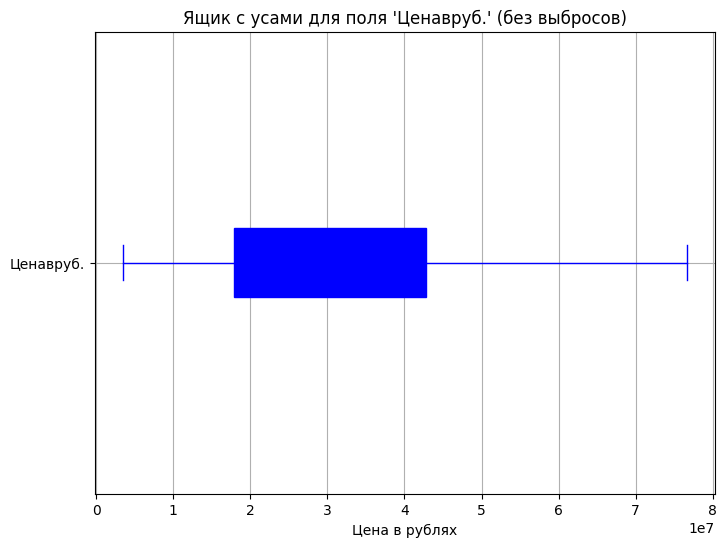

In [21]:
# Удаляем строки с выбросами
df_cleaned = df_cleaned[df_cleaned['Ценавруб.'] <= upper_bound]

# Проверяем результат
print("Количество строк после удаления выбросов:", len(df_cleaned))

# Построение boxplot для поля 'Ценавруб.' после удаления выбросов
plt.figure(figsize=(8, 6))  # Задаем размер графика
df_cleaned.boxplot(column='Ценавруб.', vert=False, color='blue', patch_artist=True)
plt.title("Ящик с усами для поля 'Ценавруб.' (без выбросов)")
plt.xlabel("Цена в рублях")
plt.show()

**Кодирование категориальных переменных**

In [22]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

encoded_data = encoder.fit_transform(df_cleaned[['Новостройка', 'Метро.Район']])

encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['Новостройка', 'Метро.Район']))

df_encoded = pd.concat([df_cleaned.drop(['Новостройка', 'Метро.Район'], axis=1), encoded_df], axis=1)

print("Первые 5 строк после кодирования:")
print(df_encoded.head())

Первые 5 строк после кодирования:
   Комнатность  Время.до.метро  Этаж  Этажность  Площадь.общая  Площадь.кухни  \
0          1.0            15.0   4.0        9.0           21.0            4.0   
1          1.0            10.0   5.0        5.0           31.0            6.0   
2          1.0            10.0   5.0        5.0           32.0            7.0   
3          1.0             5.0   1.0        9.0           36.0            8.0   
4          2.0            10.0   5.0        5.0           41.0            6.0   

   Ценавруб.  Новостройка_Нет  Метро.Район_Арбатская  Метро.Район_Баррикадная  \
0  3500000.0              1.0                    0.0                      0.0   
1  4700000.0              1.0                    0.0                      0.0   
2  5000000.0              1.0                    0.0                      0.0   
3  5350000.0              1.0                    0.0                      0.0   
4  5350000.0              1.0                    0.0                      

In [23]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1893 entries, 0 to 1557
Data columns (total 49 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Комнатность                        1558 non-null   float64
 1   Время.до.метро                     1558 non-null   float64
 2   Этаж                               1558 non-null   float64
 3   Этажность                          1558 non-null   float64
 4   Площадь.общая                      1558 non-null   float64
 5   Площадь.кухни                      1558 non-null   float64
 6   Ценавруб.                          1558 non-null   float64
 7   Новостройка_Нет                    1558 non-null   float64
 8   Метро.Район_Арбатская              1558 non-null   float64
 9   Метро.Район_Баррикадная            1558 non-null   float64
 10  Метро.Район_Белорусская            1558 non-null   float64
 11  Метро.Район_Библиотека им. Ленина  1558 non-null   float64
 1

In [24]:
# Удаляем текстовые поля
text_columns = df_cleaned.select_dtypes(include=['object']).columns
df_cleaned = df_cleaned.drop(columns=text_columns)

# Применяем One-Hot Encoding
df_encoded = pd.get_dummies(df_cleaned, drop_first=True)

# Проверяем результат
print("Столбцы после One-Hot Encoding:")
print(df_encoded.columns)

# Проверяем типы данных
print("\nТипы данных всех столбцов:")
print(df_encoded.dtypes)

Столбцы после One-Hot Encoding:
Index(['Комнатность', 'Время.до.метро', 'Этаж', 'Этажность', 'Площадь.общая',
       'Площадь.кухни', 'Ценавруб.'],
      dtype='object')

Типы данных всех столбцов:
Комнатность         int64
Время.до.метро    float64
Этаж              float64
Этажность         float64
Площадь.общая     float64
Площадь.кухни     float64
Ценавруб.         float64
dtype: object


**Формирование обучающего и тестового множества**

In [70]:
# Входные данные (X) — все столбцы, кроме 'Ценавруб.'
X = df_encoded.drop(columns=['Ценавруб.'])

# Выходные данные (y) — столбец 'Ценавруб.'
y = df_encoded['Ценавруб.']

# Определяем размер обучающей выборки
train_size = len(df_encoded) - 300

# Разделяем данные: первые (train_size) записи в обучение, последние 300 в тест
X_learn, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_learn, y_test = y.iloc[:train_size], y.iloc[train_size:]

# Проверяем размеры выборок
print("Размеры обучающей выборки (X_learn, y_learn):", X_learn.shape, y_learn.shape)
print("Размеры тестовой выборки (X_test, y_test):", X_test.shape, y_test.shape)

Размеры обучающей выборки (X_learn, y_learn): (1258, 6) (1258,)
Размеры тестовой выборки (X_test, y_test): (300, 6) (300,)


**Обучение метрик**

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [72]:
# Обучаем модель (пример)
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_learn, y_learn)

# Делаем предсказания на тестовых данных
y_pred = model.predict(X_test)

# Вычисляем метрики
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print("Средняя абсолютная ошибка (MAE):", mae)
print("Среднеквадратичная ошибка (MSE):", mse)
print("Коэффициент детерминации (R²):", r2)

Средняя абсолютная ошибка (MAE): 15269443.204950675
Среднеквадратичная ошибка (MSE): 341225779834500.8
Коэффициент детерминации (R²): -2.764467925915924


# **Линейная регрессия**

Обучающая выборка:
MAE: 3999549.75, MSE: 29308250817919.53, RMSE: 5413709.52, R²: 0.76
Тестовая выборка:
MAE: 15269443.20, MSE: 341225779834500.81, RMSE: 18472297.63, R²: -2.76


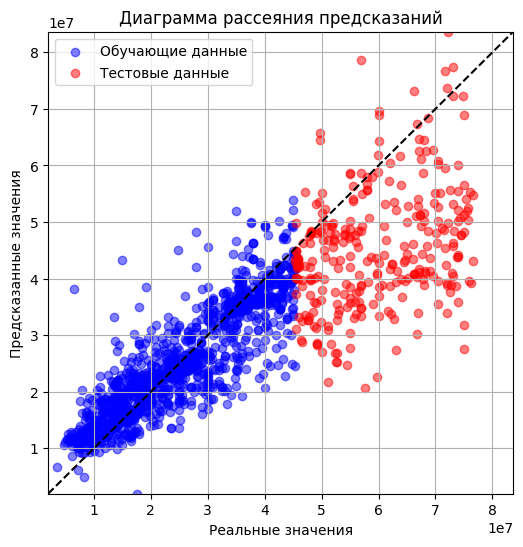

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Создаем и обучаем модель линейной регрессии
model = LinearRegression()
model.fit(X_learn, y_learn)

# Предсказания
y_train_pred = model.predict(X_learn)
y_test_pred = model.predict(X_test)

# Вычисляем ошибки
train_mae = mean_absolute_error(y_learn, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_mse = mean_squared_error(y_learn, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_learn, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Вывод метрик
print("Обучающая выборка:")
print(f"MAE: {train_mae:.2f}, MSE: {train_mse:.2f}, RMSE: {train_rmse:.2f}, R²: {train_r2:.2f}")
print("Тестовая выборка:")
print(f"MAE: {test_mae:.2f}, MSE: {test_mse:.2f}, RMSE: {test_rmse:.2f}, R²: {test_r2:.2f}")

# Функция визуализации
def plot_results(y_real_train, y_pred_train, y_real_test, y_pred_test):
    plt.figure(figsize=(6, 6))

    # Границы осей
    min_val = min(y_real_train.min(), y_real_test.min(), y_pred_train.min(), y_pred_test.min())
    max_val = max(y_real_train.max(), y_real_test.max(), y_pred_train.max(), y_pred_test.max())

    # Диаграмма рассеяния
    plt.scatter(y_real_train, y_pred_train, color='blue', alpha=0.5, label="Обучающие данные")
    plt.scatter(y_real_test, y_pred_test, color='red', alpha=0.5, label="Тестовые данные")

    # Главная диагональ
    plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', color='black')

    # Настройки графика
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.xlabel("Реальные значения")
    plt.ylabel("Предсказанные значения")
    plt.legend()
    plt.title("Диаграмма рассеяния предсказаний")
    plt.grid()
    plt.show()

# Визуализация результатов
plot_results(y_learn, y_train_pred, y_test, y_test_pred)

# **Регуляризируемая линейная регрессия**

Ridge (alpha=0.01):
  Train: MAE = 3999567.8218, MSE = 29308250850331.0156, RMSE = 5413709.5277, R² = 0.7589
  Test:  MAE = 15269653.2647, MSE = 341232716524445.8750, RMSE = 18472485.3911, R² = -2.7645
Ridge (alpha=0.1):
  Train: MAE = 3999730.4195, MSE = 29308254056553.0234, RMSE = 5413709.8238, R² = 0.7589
  Test:  MAE = 15271543.0774, MSE = 341295135528231.2500, RMSE = 18474174.8267, R² = -2.7652
Ridge (alpha=1):
  Train: MAE = 4001414.9134, MSE = 29308572183544.4961, RMSE = 5413739.2054, R² = 0.7589
  Test:  MAE = 15290369.7168, MSE = 341918216659027.4375, RMSE = 18491030.7084, R² = -2.7721
Ridge (alpha=10):
  Train: MAE = 4020869.9621, MSE = 29338046875684.7188, RMSE = 5416460.7333, R² = 0.7587
  Test:  MAE = 15475535.6706, MSE = 348038758382598.9375, RMSE = 18655796.9109, R² = -2.8396
Ridge (alpha=100):
  Train: MAE = 4259251.5977, MSE = 30915800605477.3164, RMSE = 5560197.8927, R² = 0.7457
  Test:  MAE = 16973537.6076, MSE = 399547812794513.6875, RMSE = 19988692.1232, R² = -3.40

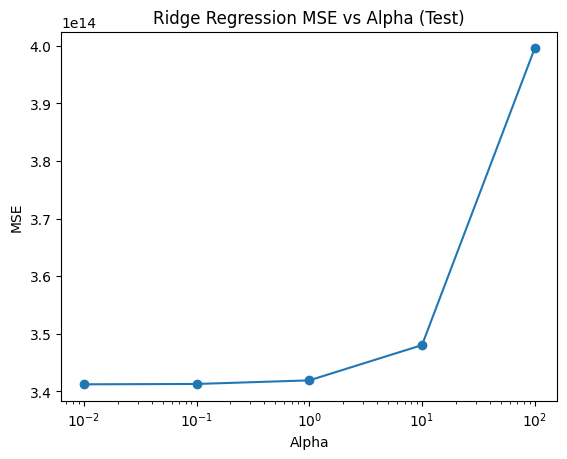

LASSO (alpha=0.01):
  Train: MAE = 3999549.7528, MSE = 29308250817919.5312, RMSE = 5413709.5247, R² = 0.7589
  Test:  MAE = 15269443.2481, MSE = 341225781397894.0000, RMSE = 18472297.6751, R² = -2.7645
LASSO (alpha=0.1):
  Train: MAE = 3999549.7879, MSE = 29308250817919.7461, RMSE = 5413709.5247, R² = 0.7589
  Test:  MAE = 15269443.6354, MSE = 341225795442564.1875, RMSE = 18472298.0553, R² = -2.7645
LASSO (alpha=1):
  Train: MAE = 3999550.1402, MSE = 29308250817941.3789, RMSE = 5413709.5247, R² = 0.7589
  Test:  MAE = 15269447.5154, MSE = 341225936119699.4375, RMSE = 18472301.8631, R² = -2.7645
LASSO (alpha=10):
  Train: MAE = 3999553.6683, MSE = 29308250820113.7422, RMSE = 5413709.5249, R² = 0.7589
  Test:  MAE = 15269486.3752, MSE = 341227345146775.0625, RMSE = 18472340.0019, R² = -2.7645
LASSO (alpha=100):
  Train: MAE = 3999588.8685, MSE = 29308251036200.3164, RMSE = 5413709.5449, R² = 0.7589
  Test:  MAE = 15269874.0997, MSE = 341241403518506.7500, RMSE = 18472720.5229, R² = -2.76

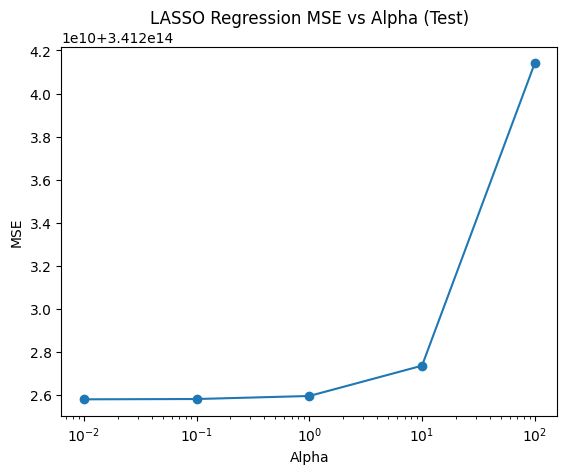

Elastic-Net (alpha=0.01, l1_ratio=0.2):
  Train: MAE = 4021015.5585, MSE = 29338413607955.5742, RMSE = 5416494.5867, R² = 0.7587
  Test:  MAE = 15476823.8128, MSE = 348081569619649.8125, RMSE = 18656944.2734, R² = -2.8401
Elastic-Net (alpha=0.01, l1_ratio=0.5):
  Train: MAE = 4012536.7923, MSE = 29320407877602.5195, RMSE = 5414832.2114, R² = 0.7588
  Test:  MAE = 15399825.8366, MSE = 345539926833604.8125, RMSE = 18588704.2807, R² = -2.8121
Elastic-Net (alpha=0.01, l1_ratio=0.8):
  Train: MAE = 4004383.5580, MSE = 29310258941291.9180, RMSE = 5413894.9880, R² = 0.7589
  Test:  MAE = 15321887.2718, MSE = 342963210222041.8125, RMSE = 18519265.9202, R² = -2.7836
Elastic-Net (alpha=0.1, l1_ratio=0.2):
  Train: MAE = 4260869.3167, MSE = 30930457576789.5469, RMSE = 5561515.7625, R² = 0.7456
  Test:  MAE = 16982318.1116, MSE = 399860950522707.9375, RMSE = 19996523.4609, R² = -3.4113
Elastic-Net (alpha=0.1, l1_ratio=0.5):
  Train: MAE = 4162091.6128, MSE = 30107441693297.0312, RMSE = 5487024.849

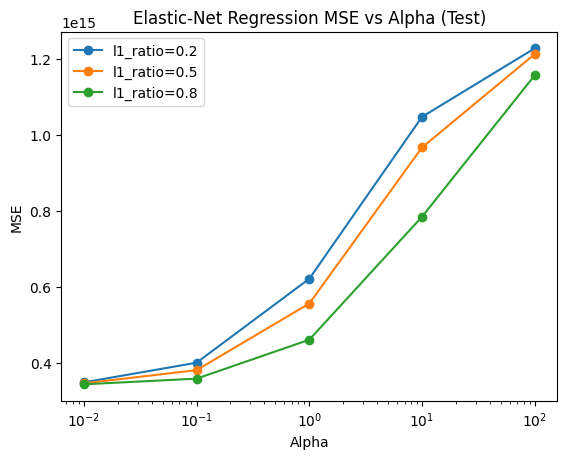

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Масштабирование данных
scaler = StandardScaler()
X_learn_scaled = scaler.fit_transform(X_learn)
X_test_scaled = scaler.transform(X_test)

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Создание модели Ridge с разными значениями alpha
alphas = [0.01, 0.1, 1, 10, 100]
ridge_results = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, max_iter=1000, tol=1e-4)
    ridge.fit(X_learn_scaled, y_learn)

    # Предсказания для обучающей и тестовой выборок
    y_train_pred = ridge.predict(X_learn_scaled)
    y_test_pred = ridge.predict(X_test_scaled)

    # Вычисление метрик для обучающей и тестовой выборок
    train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)
    test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

    # Сохранение результатов
    ridge_results.append({
        'alpha': alpha,
        'train_mae': train_mae, 'train_mse': train_mse, 'train_rmse': train_rmse, 'train_r2': train_r2,
        'test_mae': test_mae, 'test_mse': test_mse, 'test_rmse': test_rmse, 'test_r2': test_r2
    })

    # Вывод результатов
    print(f'Ridge (alpha={alpha}):')
    print(f'  Train: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
    print(f'  Test:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация результатов Ridge (MSE на тестовой выборке)
ridge_test_mse = [result['test_mse'] for result in ridge_results]
plt.plot(alphas, ridge_test_mse, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('Ridge Regression MSE vs Alpha (Test)')
plt.show()

# Создание модели LASSO с разными значениями alpha
lasso_results = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=1000, tol=1e-4)
    lasso.fit(X_learn_scaled, y_learn)

    # Предсказания для обучающей и тестовой выборок
    y_train_pred = lasso.predict(X_learn_scaled)
    y_test_pred = lasso.predict(X_test_scaled)

    # Вычисление метрик для обучающей и тестовой выборок
    train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)
    test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

    # Сохранение результатов
    lasso_results.append({
        'alpha': alpha,
        'train_mae': train_mae, 'train_mse': train_mse, 'train_rmse': train_rmse, 'train_r2': train_r2,
        'test_mae': test_mae, 'test_mse': test_mse, 'test_rmse': test_rmse, 'test_r2': test_r2
    })

    # Вывод результатов
    print(f'LASSO (alpha={alpha}):')
    print(f'  Train: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
    print(f'  Test:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация результатов LASSO (MSE на тестовой выборке)
lasso_test_mse = [result['test_mse'] for result in lasso_results]
plt.plot(alphas, lasso_test_mse, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('LASSO Regression MSE vs Alpha (Test)')
plt.show()

# Создание модели Elastic-Net с разными значениями alpha и l1_ratio
elastic_results = []
l1_ratios = [0.2, 0.5, 0.8]

for alpha in alphas:
    for l1_ratio in l1_ratios:
        elastic = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=1000, tol=1e-4)
        elastic.fit(X_learn_scaled, y_learn)

        # Предсказания для обучающей и тестовой выборок
        y_train_pred = elastic.predict(X_learn_scaled)
        y_test_pred = elastic.predict(X_test_scaled)

        # Вычисление метрик для обучающей и тестовой выборок
        train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)
        test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

        # Сохранение результатов
        elastic_results.append({
            'alpha': alpha, 'l1_ratio': l1_ratio,
            'train_mae': train_mae, 'train_mse': train_mse, 'train_rmse': train_rmse, 'train_r2': train_r2,
            'test_mae': test_mae, 'test_mse': test_mse, 'test_rmse': test_rmse, 'test_r2': test_r2
        })

        # Вывод результатов
        print(f'Elastic-Net (alpha={alpha}, l1_ratio={l1_ratio}):')
        print(f'  Train: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
        print(f'  Test:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация результатов Elastic-Net (MSE на тестовой выборке)
for l1_ratio in l1_ratios:
    scores = [result['test_mse'] for result in elastic_results if result['l1_ratio'] == l1_ratio]
    plt.plot(alphas, scores, marker='o', label=f'l1_ratio={l1_ratio}')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('Elastic-Net Regression MSE vs Alpha (Test)')
plt.legend()
plt.show()

Ridge (alpha=0.01): MSE = 341232716524445.9
Ridge (alpha=0.1): MSE = 341295135528231.25
Ridge (alpha=1): MSE = 341918216659027.44
Ridge (alpha=10): MSE = 348038758382598.94
Ridge (alpha=100): MSE = 399547812794513.7


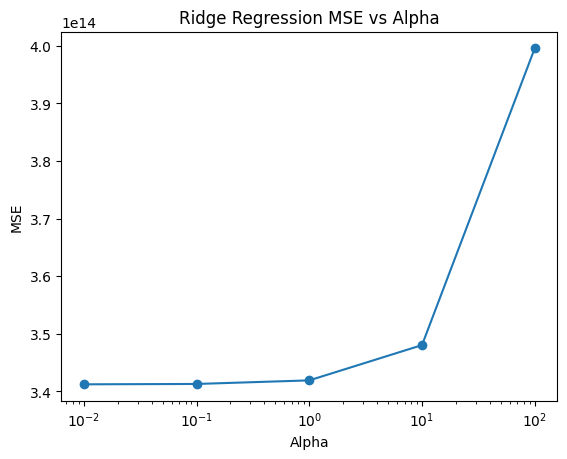

LASSO (alpha=0.01): MSE = 341225781397894.0
LASSO (alpha=0.1): MSE = 341225795442564.2
LASSO (alpha=1): MSE = 341225936119699.44
LASSO (alpha=10): MSE = 341227345146775.06
LASSO (alpha=100): MSE = 341241403518506.75


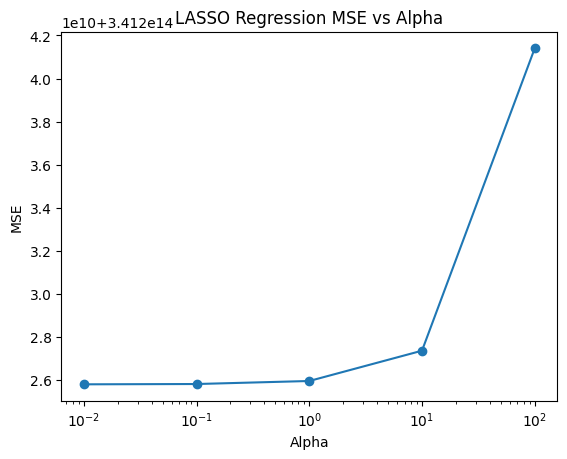

Elastic-Net (alpha=0.01, l1_ratio=0.2): MSE = 348081569619649.8
Elastic-Net (alpha=0.01, l1_ratio=0.5): MSE = 345539926833604.8
Elastic-Net (alpha=0.01, l1_ratio=0.8): MSE = 342963210222041.8
Elastic-Net (alpha=0.1, l1_ratio=0.2): MSE = 399860950522707.94
Elastic-Net (alpha=0.1, l1_ratio=0.5): MSE = 380240950185830.75
Elastic-Net (alpha=0.1, l1_ratio=0.8): MSE = 357904933672165.2
Elastic-Net (alpha=1, l1_ratio=0.2): MSE = 620844322583827.4
Elastic-Net (alpha=1, l1_ratio=0.5): MSE = 555552090121322.25
Elastic-Net (alpha=1, l1_ratio=0.8): MSE = 460318885094681.56
Elastic-Net (alpha=10, l1_ratio=0.2): MSE = 1047053998236460.4
Elastic-Net (alpha=10, l1_ratio=0.5): MSE = 966500743472657.5
Elastic-Net (alpha=10, l1_ratio=0.8): MSE = 784091048737855.4
Elastic-Net (alpha=100, l1_ratio=0.2): MSE = 1227503913444491.0
Elastic-Net (alpha=100, l1_ratio=0.5): MSE = 1212245103887815.0
Elastic-Net (alpha=100, l1_ratio=0.8): MSE = 1156621773548275.8


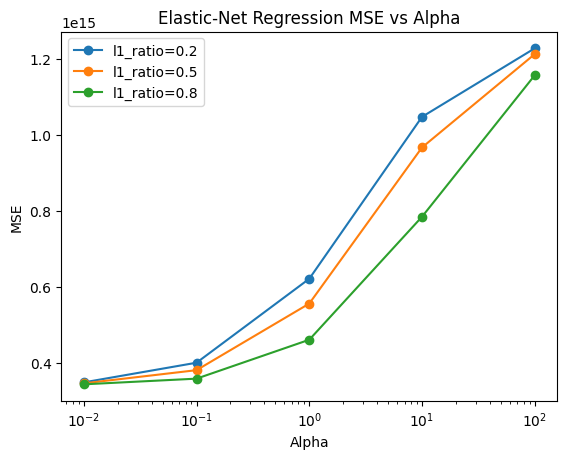

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# Масштабирование данных
scaler = StandardScaler()
X_learn_scaled = scaler.fit_transform(X_learn)
X_test_scaled = scaler.transform(X_test)

# Создание модели Ridge с разными значениями alpha
alphas = [0.01, 0.1, 1, 10, 100]
ridge_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, max_iter=1000, tol=1e-4)
    ridge.fit(X_learn_scaled, y_learn)
    y_pred = ridge.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    ridge_scores.append(mse)
    print(f'Ridge (alpha={alpha}): MSE = {mse}')

# Визуализация результатов
plt.plot(alphas, ridge_scores, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('Ridge Regression MSE vs Alpha')
plt.show()

# Создание модели LASSO с разными значениями alpha
lasso_scores = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=1000, tol=1e-4)
    lasso.fit(X_learn_scaled, y_learn)
    y_pred = lasso.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    lasso_scores.append(mse)
    print(f'LASSO (alpha={alpha}): MSE = {mse}')

# Визуализация результатов
plt.plot(alphas, lasso_scores, marker='o')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('LASSO Regression MSE vs Alpha')
plt.show()

# Создание модели Elastic-Net с разными значениями alpha и l1_ratio
elastic_scores = []
l1_ratios = [0.2, 0.5, 0.8]

for alpha in alphas:
    for l1_ratio in l1_ratios:
        elastic = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=1000, tol=1e-4)
        elastic.fit(X_learn_scaled, y_learn)
        y_pred = elastic.predict(X_test_scaled)
        mse = mean_squared_error(y_test, y_pred)
        elastic_scores.append((alpha, l1_ratio, mse))
        print(f'Elastic-Net (alpha={alpha}, l1_ratio={l1_ratio}): MSE = {mse}')

# Визуализация результатов
for l1_ratio in l1_ratios:
    scores = [mse for (a, lr, mse) in elastic_scores if lr == l1_ratio]
    plt.plot(alphas, scores, marker='o', label=f'l1_ratio={l1_ratio}')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('MSE')
plt.title('Elastic-Net Regression MSE vs Alpha')
plt.legend()
plt.show()

1. Ridge-регуляризация незначительно снижает уровень переобучения при малых значениях alpha, но при больших значениях alpha модель становится слишком простой, что ухудшает её качество.
2. LASSO-регуляризация не снижает уровень переобучения в данном случае, так как MSE остаётся практически неизменным. Возможно, данные не содержат избыточных признаков, или модель уже достаточно проста.
3. Elastic-Net показывает худшие результаты по сравнению с Ridge и LASSO. Это может быть связано с тем, что комбинация L1 и L2 регуляризации не подходит для данных, либо параметры alpha и l1_ratio выбраны неоптимально.

# **Деревья решений**

Метрики на обучающей выборке:
  MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994

Метрики на тестовой выборке:
  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343


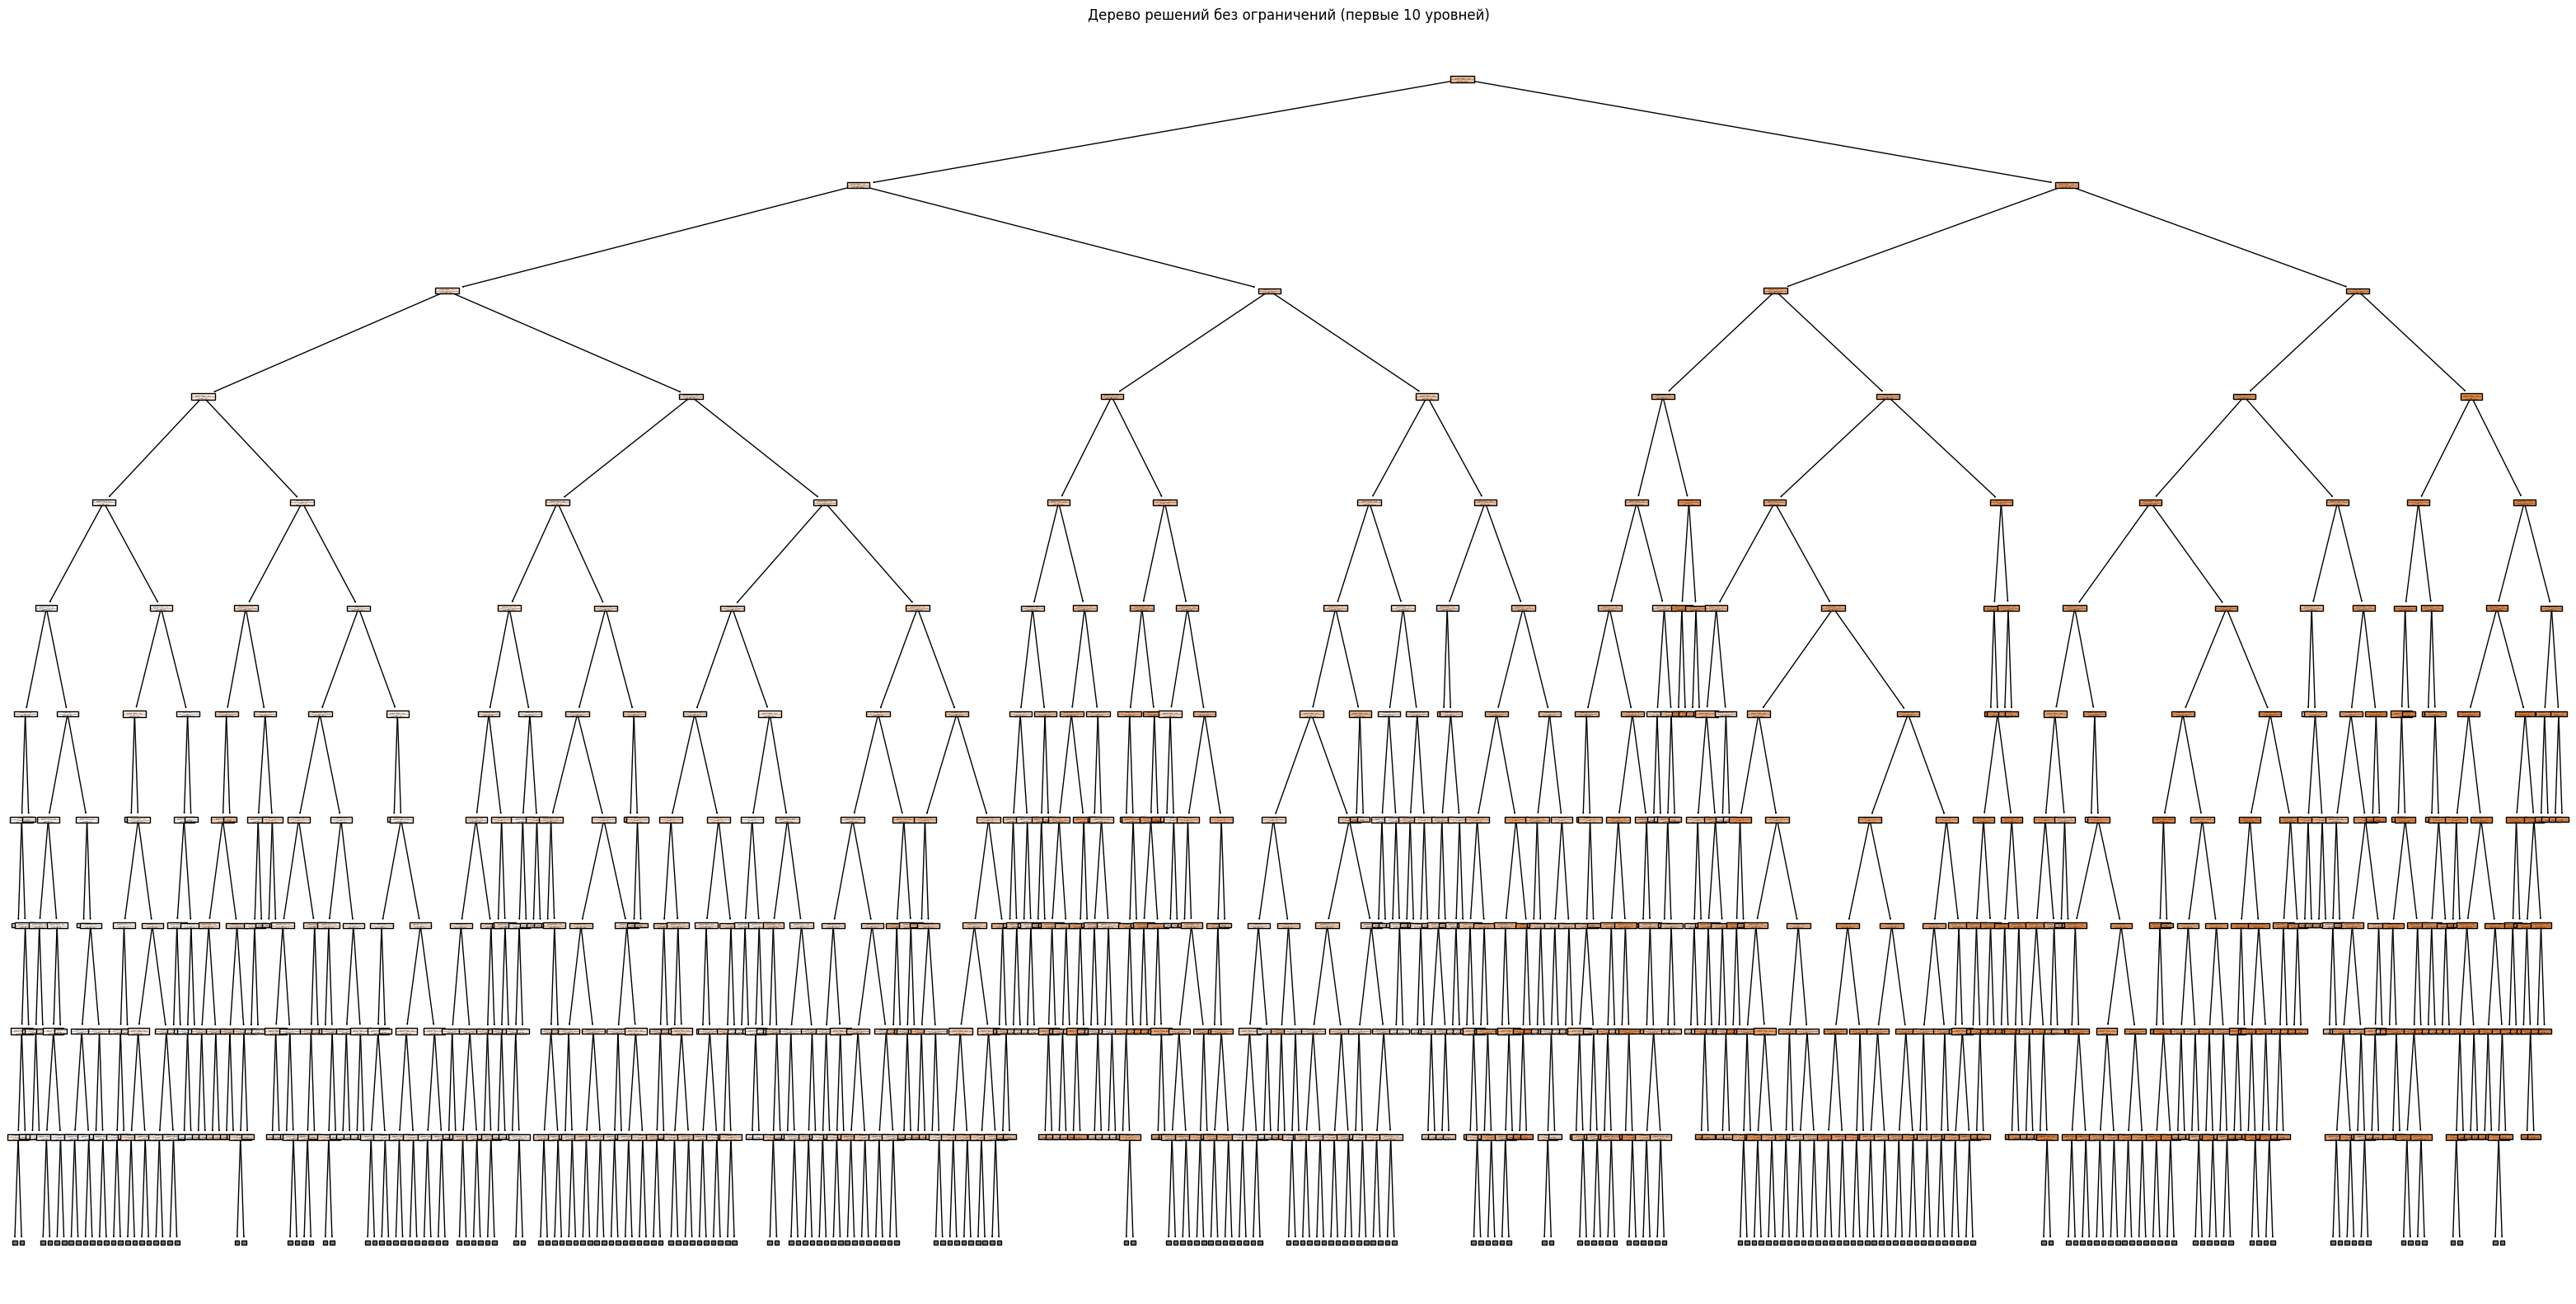

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Создание модели дерева решений без ограничений
tree_unlimited = DecisionTreeRegressor(random_state=42)
tree_unlimited.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = tree_unlimited.predict(X_learn)
y_test_pred = tree_unlimited.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Вывод результатов
print("Метрики на обучающей выборке:")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке:")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

# Визуализация дерева с большим количеством уровней
plt.figure(figsize=(40, 20))  # Увеличиваем размер фигуры для лучшей читаемости
plot_tree(tree_unlimited, filled=True, feature_names=X.columns, max_depth=10)  # Увеличиваем max_depth до 10
plt.title("Дерево решений без ограничений (первые 10 уровней)")
plt.show()

MSE модели без ограничений: 537904352353658.0


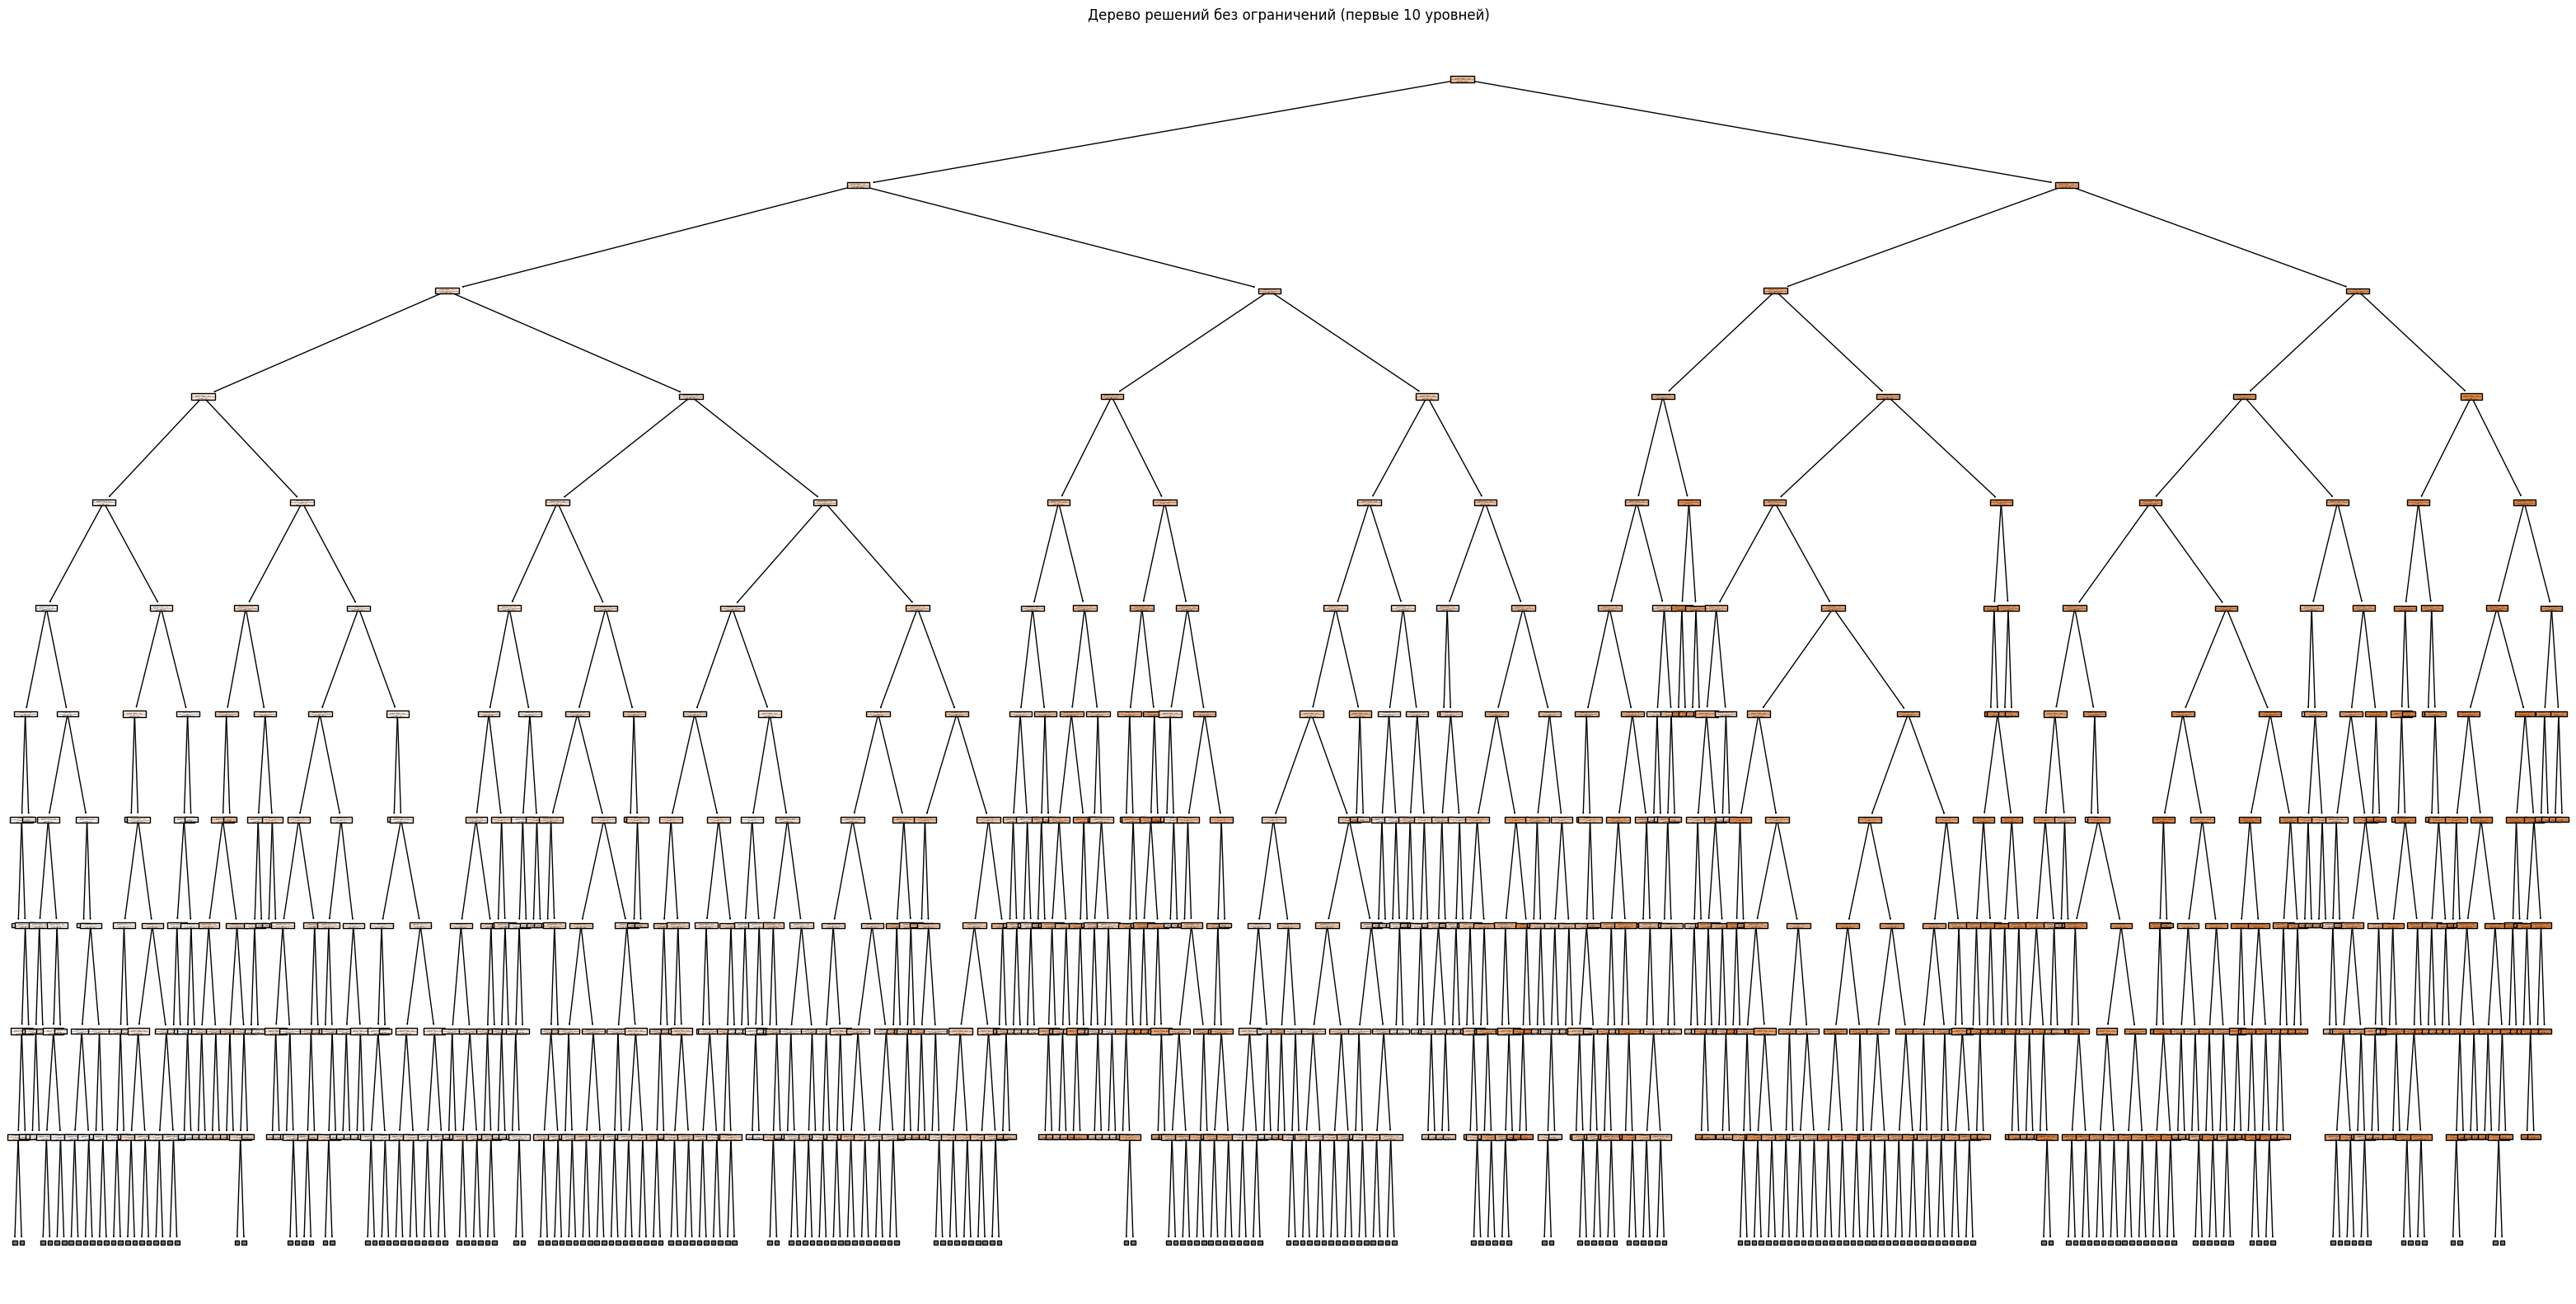

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error

# Создание модели дерева решений без ограничений
tree_unlimited = DecisionTreeRegressor(random_state=42)
tree_unlimited.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred_unlimited = tree_unlimited.predict(X_test)
mse_unlimited = mean_squared_error(y_test, y_pred_unlimited)
print(f'MSE модели без ограничений: {mse_unlimited}')

# Визуализация дерева с большим количеством уровней
plt.figure(figsize=(40, 20))  # Увеличиваем размер фигуры для лучшей читаемости
plot_tree(tree_unlimited, filled=True, feature_names=X.columns, max_depth=10)  # Увеличиваем max_depth до 10
plt.title("Дерево решений без ограничений (первые 10 уровней)")
plt.show()

MSE при max_depth=1: 685010974940730.6
MSE при max_depth=2: 571620552572107.4
MSE при max_depth=3: 571978082317616.9
MSE при max_depth=4: 587436924443053.5
MSE при max_depth=5: 572385418002966.2
MSE при max_depth=6: 539421228771802.1
MSE при max_depth=7: 524643690956143.8
MSE при max_depth=8: 529792933446147.2
MSE при max_depth=9: 558171903549367.56
MSE при max_depth=10: 530177655082522.25
MSE при max_depth=11: 540023658186216.6
MSE при max_depth=12: 546243624468791.56
MSE при max_depth=13: 550384931224144.56
MSE при max_depth=14: 559207383409773.6
MSE при max_depth=15: 570979864958740.6
MSE при max_depth=16: 542676448136789.0
MSE при max_depth=17: 565053215388465.6
MSE при max_depth=18: 545053500177816.1
MSE при max_depth=19: 570297920547660.8
MSE при max_depth=20: 554836978240649.6


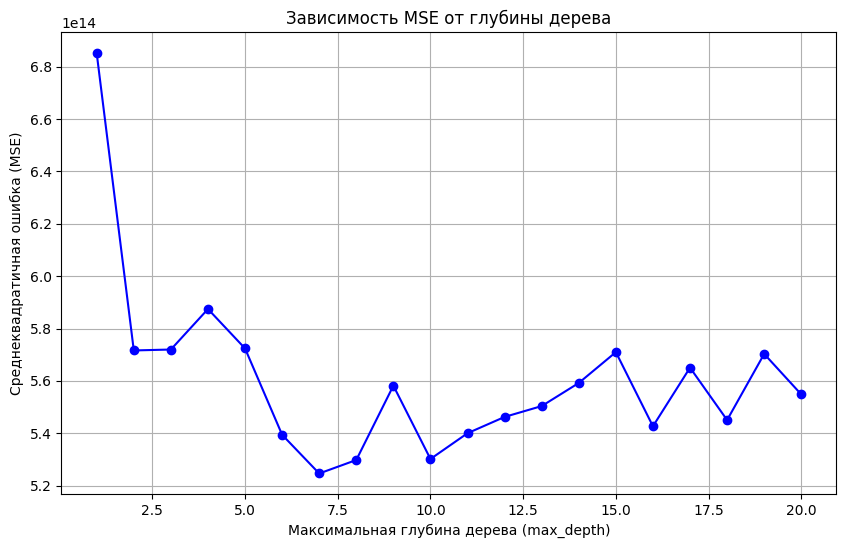

In [45]:
# Пробуем разные значения max_depth
max_depths = range(1, 21)  # Пробуем глубину от 1 до 20
mse_values = []

for depth in max_depths:
    # Создаем модель с ограничением глубины
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_learn, y_learn)  # Обучаем модель
    y_pred = tree.predict(X_test)  # Прогнозируем на тестовой выборке
    mse = mean_squared_error(y_test, y_pred)  # Вычисляем MSE
    mse_values.append(mse)
    print(f'MSE при max_depth={depth}: {mse}')

# Визуализация зависимости MSE от max_depth
plt.figure(figsize=(10, 6))
plt.plot(max_depths, mse_values, marker='o', linestyle='-', color='b')
plt.xlabel('Максимальная глубина дерева (max_depth)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от глубины дерева')
plt.grid(True)
plt.show()

Метрики при max_depth=1:
  Обучающая выборка: MAE = 5843367.1575, MSE = 52419531420598.8594, RMSE = 7240133.3842, R² = 0.5688
  Тестовая выборка:  MAE = 24326423.3499, MSE = 685010974940730.6250, RMSE = 26172714.3212, R² = -6.5572
Метрики при max_depth=2:
  Обучающая выборка: MAE = 4724431.8797, MSE = 36828257895631.0156, RMSE = 6068628.9964, R² = 0.6971
  Тестовая выборка:  MAE = 22000560.0714, MSE = 571620552572107.3750, RMSE = 23908587.4232, R² = -5.3062
Метрики при max_depth=3:
  Обучающая выборка: MAE = 4016432.5980, MSE = 29503188391055.6055, RMSE = 5431683.7529, R² = 0.7573
  Тестовая выборка:  MAE = 21869030.5846, MSE = 571978082317616.8750, RMSE = 23916063.2696, R² = -5.3102
Метрики при max_depth=4:
  Обучающая выборка: MAE = 3700395.7663, MSE = 25849199758462.1992, RMSE = 5084210.8295, R² = 0.7874
  Тестовая выборка:  MAE = 22058300.1120, MSE = 587436924443053.5000, RMSE = 24237098.1028, R² = -5.4807
Метрики при max_depth=5:
  Обучающая выборка: MAE = 3462682.3697, MSE = 2252

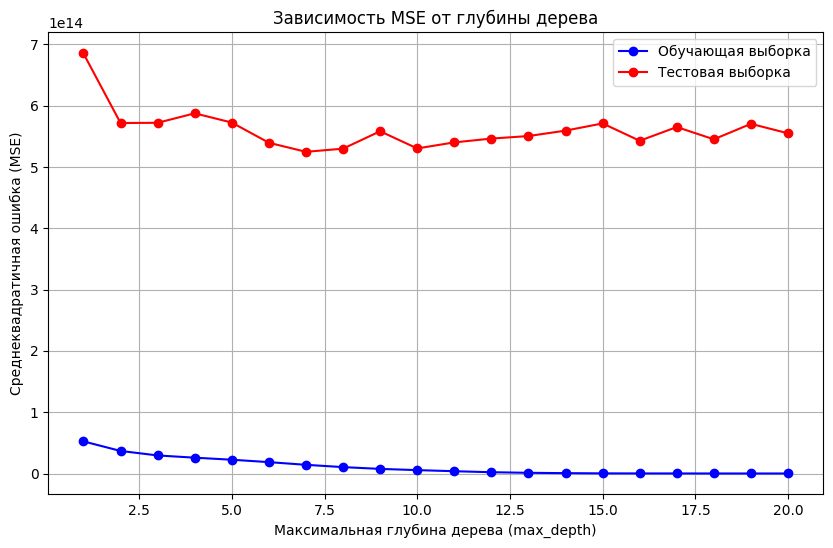

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Пробуем разные значения max_depth
max_depths = range(1, 21)  # Пробуем глубину от 1 до 20
train_metrics = []
test_metrics = []

for depth in max_depths:
    # Создаем модель с ограничением глубины
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_learn, y_learn)  # Обучаем модель

    # Предсказание на обучающей и тестовой выборках
    y_train_pred = tree.predict(X_learn)
    y_test_pred = tree.predict(X_test)

    # Вычисление метрик на обучающей выборке
    train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

    # Вычисление метрик на тестовой выборке
    test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

    # Сохранение результатов
    train_metrics.append((train_mae, train_mse, train_rmse, train_r2))
    test_metrics.append((test_mae, test_mse, test_rmse, test_r2))

    # Вывод результатов
    print(f'Метрики при max_depth={depth}:')
    print(f'  Обучающая выборка: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
    print(f'  Тестовая выборка:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация зависимости MSE от max_depth
plt.figure(figsize=(10, 6))
plt.plot(max_depths, [mse for _, mse, _, _ in train_metrics], marker='o', linestyle='-', color='b', label='Обучающая выборка')
plt.plot(max_depths, [mse for _, mse, _, _ in test_metrics], marker='o', linestyle='-', color='r', label='Тестовая выборка')
plt.xlabel('Максимальная глубина дерева (max_depth)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от глубины дерева')
plt.legend()
plt.grid(True)
plt.show()

При max_depth=1 дерево очень простое (фактически это "пень" с одним разделением), поэтому оно не может уловить сложные зависимости в данных.

При увеличении глубины до 2 и 3 MSE снижается, но остается высоким, так как дерево всё ещё слишком простое.

Вывод:

Модель недообучается (high bias), так как её сложность недостаточна для описания данных.

При увеличении глубины дерева до 6–7 MSE достигает минимальных значений.

Наименьшее значение MSE наблюдается при max_depth=7 (524643690956143.8).

Это указывает на то, что дерево с глубиной 7 лучше всего балансирует между недообучением и переобучением.

Вывод:

Модель с глубиной 6–7 демонстрирует наилучшее качество (наименьший MSE) на тестовой выборке.

Модель с глубиной больше 7 начинает переобучаться, что приводит к ухудшению качества на тестовой выборке.

MSE при min_samples_split=2: 537904352353658.0
MSE при min_samples_split=3: 538446862666258.75
MSE при min_samples_split=4: 542269457551728.44
MSE при min_samples_split=5: 561931570752656.2
MSE при min_samples_split=6: 538489684582885.56
MSE при min_samples_split=7: 548960723753607.9
MSE при min_samples_split=8: 552379657839381.25
MSE при min_samples_split=9: 552973756125880.94
MSE при min_samples_split=10: 555819047072786.1
MSE при min_samples_split=11: 557235169428358.0
MSE при min_samples_split=12: 559265718295569.8
MSE при min_samples_split=13: 558423835554792.3
MSE при min_samples_split=14: 560709913031343.4
MSE при min_samples_split=15: 560709913031343.4
MSE при min_samples_split=16: 561649941303537.5
MSE при min_samples_split=17: 558170325064267.06
MSE при min_samples_split=18: 557924370850063.1
MSE при min_samples_split=19: 564974617686803.0
MSE при min_samples_split=20: 565202210204557.1
MSE при min_samples_split=21: 565042973088964.6
MSE при min_samples_split=22: 564878856542

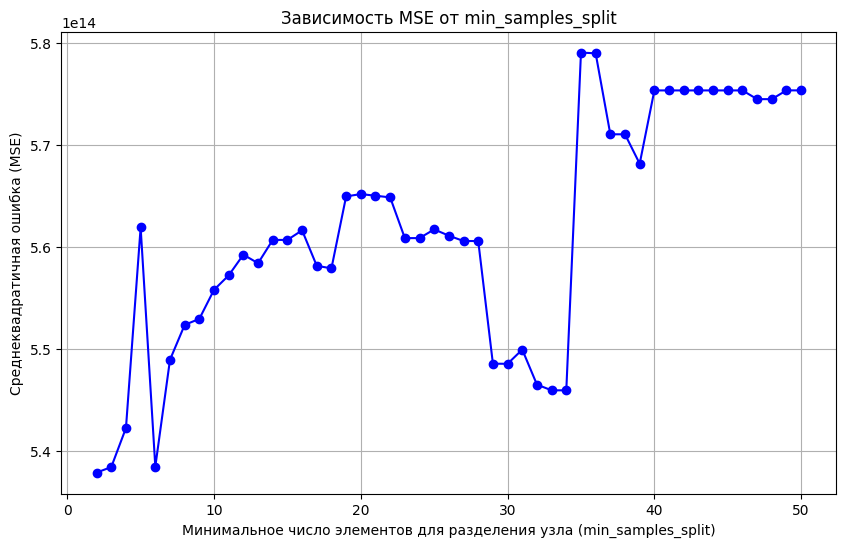

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# Пробуем разные значения min_samples_split
min_samples_splits = range(2, 51)  # Пробуем значения от 2 до 50
mse_values = []

for samples in min_samples_splits:
    # Создаем модель с ограничением min_samples_split
    tree = DecisionTreeRegressor(min_samples_split=samples, random_state=42)
    tree.fit(X_learn, y_learn)  # Обучаем модель
    y_pred = tree.predict(X_test)  # Прогнозируем на тестовой выборке
    mse = mean_squared_error(y_test, y_pred)  # Вычисляем MSE
    mse_values.append(mse)
    print(f'MSE при min_samples_split={samples}: {mse}')

# Визуализация зависимости MSE от min_samples_split
plt.figure(figsize=(10, 6))
plt.plot(min_samples_splits, mse_values, marker='o', linestyle='-', color='b')
plt.xlabel('Минимальное число элементов для разделения узла (min_samples_split)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от min_samples_split')
plt.grid(True)
plt.show()

In [81]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Создаем экземпляр DecisionTreeRegressor с ограничением на листья
dtl_model = DecisionTreeRegressor(
    min_samples_leaf=10, random_state=42      # Для воспроизводимости
)

# Обучаем модель
dtl_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = dtl_model.predict(X_learn)
y_test_pred = dtl_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Выводим результаты
print("Метрики на обучающей выборке (с ограничением на листья):")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке (с ограничением на листья):")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

Метрики на обучающей выборке (с ограничением на листья):
  MAE = 3012049.3981, MSE = 18683172106360.9805, RMSE = 4322403.5104, R² = 0.8463

Метрики на тестовой выборке (с ограничением на листья):
  MAE = 21168008.0315, MSE = 560958221347434.2500, RMSE = 23684556.6002, R² = -5.1886


Метрики при min_samples_split=2:
  Обучающая выборка: MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994
  Тестовая выборка:  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343
Метрики при min_samples_split=3:
  Обучающая выборка: MAE = 314127.6692, MSE = 500612082209.6880, RMSE = 707539.4563, R² = 0.9959
  Тестовая выборка:  MAE = 20299005.1400, MSE = 538446862666258.7500, RMSE = 23204457.8188, R² = -4.9402
Метрики при min_samples_split=4:
  Обучающая выборка: MAE = 708699.1340, MSE = 1923155377219.7100, RMSE = 1386778.7773, R² = 0.9842
  Тестовая выборка:  MAE = 20367760.9778, MSE = 542269457551728.4375, RMSE = 23286679.8310, R² = -4.9824
Метрики при min_samples_split=5:
  Обучающая выборка: MAE = 961253.8930, MSE = 2918298957047.8081, RMSE = 1708302.9465, R² = 0.9760
  Тестовая выборка:  MAE = 20616124.4222, MSE = 561931570752656.1875, RMSE = 23705095.8815, R² = -5.1993
Метрики при min_samples_split=6:
  Обучающая выборка: MAE 

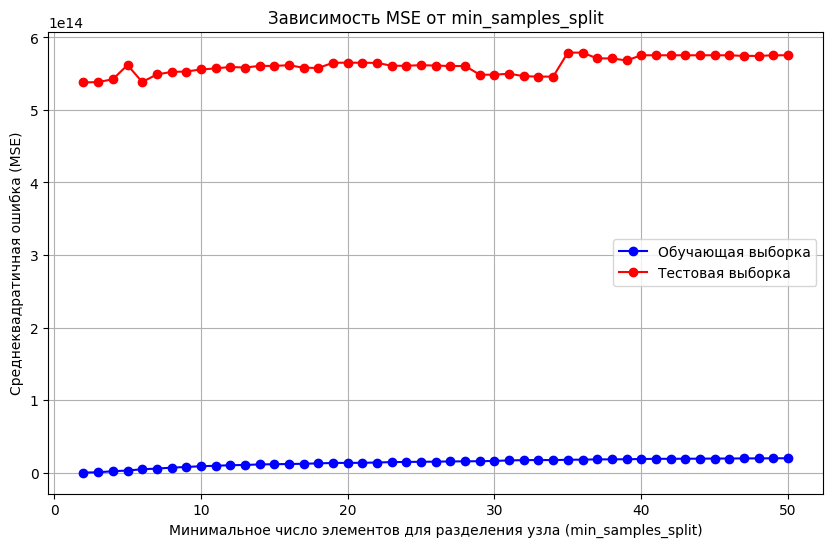

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Пробуем разные значения min_samples_split
min_samples_splits = range(2, 51)  # Пробуем значения от 2 до 50
train_metrics = []
test_metrics = []

for samples in min_samples_splits:
    # Создаем модель с ограничением min_samples_split
    tree = DecisionTreeRegressor(min_samples_split=samples, random_state=42)
    tree.fit(X_learn, y_learn)  # Обучаем модель

    # Предсказание на обучающей и тестовой выборках
    y_train_pred = tree.predict(X_learn)
    y_test_pred = tree.predict(X_test)

    # Вычисление метрик на обучающей выборке
    train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

    # Вычисление метрик на тестовой выборке
    test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

    # Сохранение результатов
    train_metrics.append((train_mae, train_mse, train_rmse, train_r2))
    test_metrics.append((test_mae, test_mse, test_rmse, test_r2))

    # Вывод результатов
    print(f'Метрики при min_samples_split={samples}:')
    print(f'  Обучающая выборка: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
    print(f'  Тестовая выборка:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация зависимости MSE от min_samples_split
plt.figure(figsize=(10, 6))
plt.plot(min_samples_splits, [mse for _, mse, _, _ in train_metrics], marker='o', linestyle='-', color='b', label='Обучающая выборка')
plt.plot(min_samples_splits, [mse for _, mse, _, _ in test_metrics], marker='o', linestyle='-', color='r', label='Тестовая выборка')
plt.xlabel('Минимальное число элементов для разделения узла (min_samples_split)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от min_samples_split')
plt.legend()
plt.grid(True)
plt.show()

Модель с малыми значениями min_samples_split не демонстрирует значительного переобучения, но и не улучшает качество.

Модель с min_samples_split в диапазоне 6–20 демонстрирует стабильное качество, но без значительного улучшения.

Оптимальное значение min_samples_split находится в диапазоне 29–34, где MSE достигает минимальных значений.

При больших значениях min_samples_split (>34) модель начинает недообучаться, так как дерево становится слишком простым и не может уловить сложные зависимости в данных.



MSE при ccp_alpha=1e-12: 537904352353658.0
MSE при ccp_alpha=1.6237767391887243e-11: 537904352353658.0
MSE при ccp_alpha=2.6366508987303556e-10: 537904352353658.0
MSE при ccp_alpha=4.281332398719396e-09: 537904352353658.0
MSE при ccp_alpha=6.951927961775605e-08: 537904352353658.0
MSE при ccp_alpha=1.1288378916846883e-06: 537904352353658.0
MSE при ccp_alpha=1.8329807108324375e-05: 537904352353658.0
MSE при ccp_alpha=0.00029763514416313134: 537904352353658.0
MSE при ccp_alpha=0.004832930238571752: 537904352353658.0
MSE при ccp_alpha=0.07847599703514622: 537904352353658.0
MSE при ccp_alpha=1.2742749857031321: 537904352353658.0
MSE при ccp_alpha=20.6913808111479: 537904352353658.0
MSE при ccp_alpha=335.98182862837876: 537904352353658.0
MSE при ccp_alpha=5455.594781168515: 537903587795331.44
MSE при ccp_alpha=88586.67904100796: 537903459236697.8
MSE при ccp_alpha=1438449.888287666: 537849709098665.6
MSE при ccp_alpha=23357214.690901212: 537776357497472.94
MSE при ccp_alpha=379269019.0732238

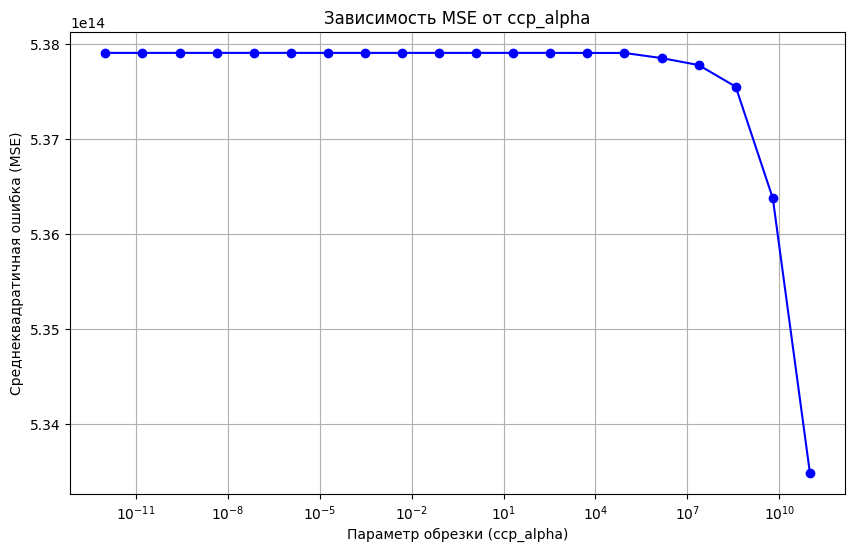

In [48]:
# Пробуем более широкий диапазон ccp_alpha
ccp_alphas = np.logspace(-12, 11, num=20)  # Пробуем значения от 1e-12 до 1e11
mse_values = []

for alpha in ccp_alphas:
    tree = DecisionTreeRegressor(ccp_alpha=alpha, random_state=42)
    tree.fit(X_learn, y_learn)
    y_pred = tree.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mse_values.append(mse)
    print(f'MSE при ccp_alpha={alpha}: {mse}')

# Визуализация зависимости MSE от ccp_alpha
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, mse_values, marker='o', linestyle='-', color='b')
plt.xscale('log')  # Логарифмическая шкала для ccp_alpha
plt.xlabel('Параметр обрезки (ccp_alpha)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от ccp_alpha')
plt.grid(True)
plt.show()

Метрики при ccp_alpha=1e-12:
  Обучающая выборка: MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994
  Тестовая выборка:  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343
Метрики при ccp_alpha=1.6237767391887243e-11:
  Обучающая выборка: MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994
  Тестовая выборка:  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343
Метрики при ccp_alpha=2.6366508987303556e-10:
  Обучающая выборка: MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994
  Тестовая выборка:  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343
Метрики при ccp_alpha=4.281332398719396e-09:
  Обучающая выборка: MAE = 58951.5198, MSE = 69329357958.2747, RMSE = 263304.6865, R² = 0.9994
  Тестовая выборка:  MAE = 20230943.3544, MSE = 537904352353658.0000, RMSE = 23192765.0864, R² = -4.9343
Метрики при ccp_alpha=6.9519279617

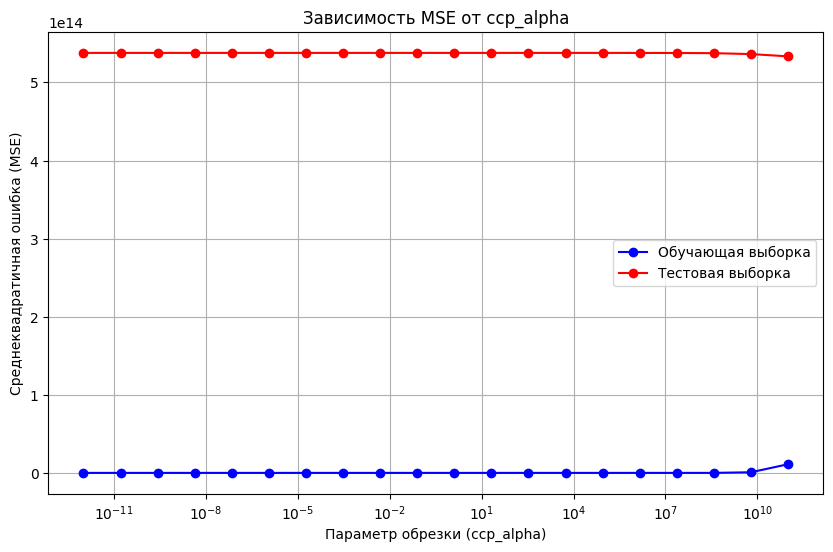

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Пробуем более широкий диапазон ccp_alpha
ccp_alphas = np.logspace(-12, 11, num=20)  # Пробуем значения от 1e-12 до 1e11
train_metrics = []
test_metrics = []

for alpha in ccp_alphas:
    # Создаем модель с параметром ccp_alpha
    tree = DecisionTreeRegressor(ccp_alpha=alpha, random_state=42)
    tree.fit(X_learn, y_learn)  # Обучаем модель

    # Предсказание на обучающей и тестовой выборках
    y_train_pred = tree.predict(X_learn)
    y_test_pred = tree.predict(X_test)

    # Вычисление метрик на обучающей выборке
    train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

    # Вычисление метрик на тестовой выборке
    test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

    # Сохранение результатов
    train_metrics.append((train_mae, train_mse, train_rmse, train_r2))
    test_metrics.append((test_mae, test_mse, test_rmse, test_r2))

    # Вывод результатов
    print(f'Метрики при ccp_alpha={alpha}:')
    print(f'  Обучающая выборка: MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}')
    print(f'  Тестовая выборка:  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}')

# Визуализация зависимости MSE от ccp_alpha
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, [mse for _, mse, _, _ in train_metrics], marker='o', linestyle='-', color='b', label='Обучающая выборка')
plt.plot(ccp_alphas, [mse for _, mse, _, _ in test_metrics], marker='o', linestyle='-', color='r', label='Тестовая выборка')
plt.xscale('log')  # Логарифмическая шкала для ccp_alpha
plt.xlabel('Параметр обрезки (ccp_alpha)')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.title('Зависимость MSE от ccp_alpha')
plt.legend()
plt.grid(True)
plt.show()

Обрезка ветвей не оказывает никакого влияния на качество модели, так как MSE не изменяется.

Это может указывать на то, что дерево решений не подвержено переобучению в текущей конфигурации, либо параметр ccp_alpha выбран в слишком узком диапазоне.

# **Ансамблевые модели (леса деревьев решений)**

In [55]:
pip install --upgrade scikit-learn

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error, r2_score

# Создаем модель бэггинга (по умолчанию используется DecisionTreeRegressor)
bagging_model = BaggingRegressor(
    n_estimators=100,  # Количество деревьев в ансамбле
    random_state=42,   # Для воспроизводимости
    n_jobs=-1          # Использовать все доступные ядра процессора
)

# Обучаем модель бэггинга
bagging_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = bagging_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели бэггинга: {mse}')
print(f'MAE модели бэггинга: {mae}')
print(f'RMSE модели бэггинга: {rmse}')
print(f'R² модели бэггинга: {r2}')

from sklearn.tree import DecisionTreeRegressor

# Обучаем одно дерево решений
single_tree = DecisionTreeRegressor(random_state=42)
single_tree.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred_tree = single_tree.predict(X_test)

# Рассчитываем метрики для одного дерева
mse_tree = mean_squared_error(y_test, y_pred_tree)
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mse_tree)
r2_tree = r2_score(y_test, y_pred_tree)

# Выводим результаты
print(f'MSE одного дерева: {mse_tree}')
print(f'MAE одного дерева: {mae_tree}')
print(f'RMSE одного дерева: {rmse_tree}')
print(f'R² одного дерева: {r2_tree}')

MSE модели бэггинга: 561141722254023.06
MAE модели бэггинга: 21186661.34628355
RMSE модели бэггинга: 23688430.13485746
R² модели бэггинга: -5.190622573543637
MSE одного дерева: 537904352353658.0
MAE одного дерева: 20230943.354444448
RMSE одного дерева: 23192765.086415593
R² одного дерева: -4.93426347396155


In [60]:
from sklearn.tree import DecisionTreeRegressor

# Создаем экземпляр DecisionTreeRegressor с настраиваемыми параметрами
base_tree = DecisionTreeRegressor(
    max_depth=10,              # Ограничиваем глубину дерева
    min_samples_split=5,       # Минимальное число образцов для разделения узла
    min_samples_leaf=2,        # Минимальное число образцов в листе
    random_state=42            # Для воспроизводимости
)
from sklearn.ensemble import BaggingRegressor

# Создаем модель бэггинга с настроенными деревьями
bagging_model = BaggingRegressor(
    estimator=base_tree,       # Используем настроенное дерево
    n_estimators=100,          # Количество деревьев в ансамбле
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора
)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Обучаем модель бэггинга
bagging_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = bagging_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели бэггинга: {mse}')
print(f'MAE модели бэггинга: {mae}')
print(f'RMSE модели бэггинга: {rmse}')
print(f'R² модели бэггинга: {r2}')

# Модель бэггинга с деревьями по умолчанию
default_bagging_model = BaggingRegressor(
    n_estimators=100,          # Количество деревьев в ансамбле
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора
)

# Обучаем модель
default_bagging_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred_default = default_bagging_model.predict(X_test)

# Оценка качества модели
mse_default = mean_squared_error(y_test, y_pred_default)
mae_default = mean_absolute_error(y_test, y_pred_default)
rmse_default = np.sqrt(mse_default)
r2_default = r2_score(y_test, y_pred_default)

# Выводим результаты
print(f'MSE модели бэггинга (по умолчанию): {mse_default}')
print(f'MAE модели бэггинга (по умолчанию): {mae_default}')
print(f'RMSE модели бэггинга (по умолчанию): {rmse_default}')
print(f'R² модели бэггинга (по умолчанию): {r2_default}')

MSE модели бэггинга: 558717788141015.06
MAE модели бэггинга: 21199704.9017331
RMSE модели бэггинга: 23637211.936711468
R² модели бэггинга: -5.163881269802232
MSE модели бэггинга (по умолчанию): 561141722254023.06
MAE модели бэггинга (по умолчанию): 21186661.34628355
RMSE модели бэггинга (по умолчанию): 23688430.13485746
R² модели бэггинга (по умолчанию): -5.190622573543637


In [80]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Создаем экземпляр DecisionTreeRegressor с настраиваемыми параметрами
base_tree = DecisionTreeRegressor(
    max_depth=10,              # Ограничиваем глубину дерева
    min_samples_split=5,       # Минимальное число образцов для разделения узла
    min_samples_leaf=2,        # Минимальное число образцов в листе
    random_state=42            # Для воспроизводимости
)

# Создаем модель бэггинга с настроенными деревьями
bagging_model = BaggingRegressor(
    estimator=base_tree,       # Используем настроенное дерево
    n_estimators=100,          # Количество деревьев в ансамбле
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора
)

# Обучаем модель бэггинга
bagging_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = bagging_model.predict(X_learn)
y_test_pred = bagging_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Выводим результаты
print("Метрики на обучающей выборке (с настроенными деревьями):")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке (с настроенными деревьями):")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

# Модель бэггинга с деревьями по умолчанию
default_bagging_model = BaggingRegressor(
    n_estimators=100,          # Количество деревьев в ансамбле
    random_state=42,           # Для воспроизводимости
    n_jobs=-1                  # Использовать все доступные ядра процессора
)

# Обучаем модель
default_bagging_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred_default = default_bagging_model.predict(X_learn)
y_test_pred_default = default_bagging_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae_default, train_mse_default, train_rmse_default, train_r2_default = calculate_metrics(y_learn, y_train_pred_default)

# Вычисление метрик на тестовой выборке
test_mae_default, test_mse_default, test_rmse_default, test_r2_default = calculate_metrics(y_test, y_test_pred_default)

# Выводим результаты
print("\nМетрики на обучающей выборке (по умолчанию):")
print(f"  MAE = {train_mae_default:.4f}, MSE = {train_mse_default:.4f}, RMSE = {train_rmse_default:.4f}, R² = {train_r2_default:.4f}")

print("\nМетрики на тестовой выборке (по умолчанию):")
print(f"  MAE = {test_mae_default:.4f}, MSE = {test_mse_default:.4f}, RMSE = {test_rmse_default:.4f}, R² = {test_r2_default:.4f}")

Метрики на обучающей выборке (с настроенными деревьями):
  MAE = 1966408.5550, MSE = 8124231718304.7666, RMSE = 2850303.7940, R² = 0.9332

Метрики на тестовой выборке (с настроенными деревьями):
  MAE = 21199704.9017, MSE = 558717788141015.0625, RMSE = 23637211.9367, R² = -5.1639

Метрики на обучающей выборке (по умолчанию):
  MAE = 1198009.7203, MSE = 3243952463197.3984, RMSE = 1801097.5718, R² = 0.9733

Метрики на тестовой выборке (по умолчанию):
  MAE = 21186661.3463, MSE = 561141722254023.0625, RMSE = 23688430.1349, R² = -5.1906


Текущие модели (с настройкой и без) работают плохо, о чём свидетельствуют высокие значения ошибок и отрицательный R².

Настройка гиперпараметров деревьев немного улучшила качество, но этого недостаточно.

Рекомендуется:

Попробовать другие значения гиперпараметров.

Использовать более мощные ансамблевые методы, такие как случайный лес или градиентный бустинг.

Провести анализ данных и улучшить их качество.

In [66]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Создаем модель градиентного бустинга
gb_model = GradientBoostingRegressor(
    n_estimators=100,          # Количество деревьев (итераций бустинга)
    learning_rate=0.1,         # Скорость обучения (вклад каждого дерева)
    max_depth=3,               # Максимальная глубина каждого дерева
    min_samples_split=2,       # Минимальное число образцов для разделения узла
    min_samples_leaf=1,        # Минимальное число образцов в листе
    random_state=42            # Для воспроизводимости
)

# Обучаем модель
gb_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = gb_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели градиентного бустинга: {mse}')
print(f'MAE модели градиентного бустинга: {mae}')
print(f'RMSE модели градиентного бустинга: {rmse}')
print(f'R² модели градиентного бустинга: {r2}')

MSE модели градиентного бустинга: 527351109639356.25
MAE модели градиентного бустинга: 20586279.826090734
RMSE модели градиентного бустинга: 22964126.58124311
R² модели градиентного бустинга: -4.8178380862558985


Модель градиентного бустинга работает плохо, о чём свидетельствуют высокие значения ошибок и отрицательный R².

In [68]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Определяем сетку параметров
param_grid = {
    'n_estimators': [50, 100, 200],  # Количество деревьев
    'learning_rate': [0.01, 0.1, 0.2],  # Скорость обучения
    'max_depth': [3, 5, 7]  # Максимальная глубина деревьев
}

# Создаем модель градиентного бустинга
gb_model = GradientBoostingRegressor(random_state=42)

# Создаем объект GridSearchCV
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Минимизируем MSE
    cv=5,  # Количество фолдов для кросс-валидации
    n_jobs=-1  # Используем все доступные ядра процессора
)

# Обучаем модель с кросс-валидацией
grid_search.fit(X_learn, y_learn)

# Выводим лучшие параметры и результат
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший MSE:", -grid_search.best_score_)
# Создаем модель с лучшими параметрами
best_gb_model = GradientBoostingRegressor(
    n_estimators=grid_search.best_params_['n_estimators'],
    learning_rate=grid_search.best_params_['learning_rate'],
    max_depth=grid_search.best_params_['max_depth'],
    random_state=42
)

# Обучаем модель
best_gb_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = best_gb_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели градиентного бустинга: {mse}')
print(f'MAE модели градиентного бустинга: {mae}')
print(f'RMSE модели градиентного бустинга: {rmse}')
print(f'R² модели градиентного бустинга: {r2}')

Лучшие параметры: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100}
Лучший MSE: 55632223202801.21
MSE модели градиентного бустинга: 526359270832654.75
MAE модели градиентного бустинга: 20243227.307743937
RMSE модели градиентного бустинга: 22942521.02173287
R² модели градиентного бустинга: -4.806895931248391


In [79]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Определяем сетку параметров
param_grid = {
    'n_estimators': [50, 100, 200],  # Количество деревьев
    'learning_rate': [0.01, 0.1, 0.2],  # Скорость обучения
    'max_depth': [3, 5, 7]  # Максимальная глубина деревьев
}

# Создаем модель градиентного бустинга
gb_model = GradientBoostingRegressor(random_state=42)

# Создаем объект GridSearchCV
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Минимизируем MSE
    cv=5,  # Количество фолдов для кросс-валидации
    n_jobs=-1  # Используем все доступные ядра процессора
)

# Обучаем модель с кросс-валидацией
grid_search.fit(X_learn, y_learn)

# Выводим лучшие параметры и результат
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший MSE:", -grid_search.best_score_)

# Создаем модель с лучшими параметрами
best_gb_model = GradientBoostingRegressor(
    n_estimators=grid_search.best_params_['n_estimators'],
    learning_rate=grid_search.best_params_['learning_rate'],
    max_depth=grid_search.best_params_['max_depth'],
    random_state=42
)

# Обучаем модель
best_gb_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = best_gb_model.predict(X_learn)
y_test_pred = best_gb_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Выводим результаты
print("\nМетрики на обучающей выборке:")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке:")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

Лучшие параметры: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100}
Лучший MSE: 55632223202801.21

Метрики на обучающей выборке:
  MAE = 2556145.5612, MSE = 13202156433421.9062, RMSE = 3633477.1822, R² = 0.8914

Метрики на тестовой выборке:
  MAE = 20243227.3077, MSE = 526359270832654.7500, RMSE = 22942521.0217, R² = -4.8069


Модель градиентного бустинга работает плохо, о чём свидетельствуют высокие значения ошибок и отрицательный R².

In [69]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Создаем модель случайных лесов
rf_model = RandomForestRegressor(
    n_estimators=100,  # Количество деревьев
    random_state=42,    # Для воспроизводимости
    n_jobs=-1           # Использовать все доступные ядра процессора
)

# Обучаем модель
rf_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = rf_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели случайных лесов: {mse}')
print(f'MAE модели случайных лесов: {mae}')
print(f'RMSE модели случайных лесов: {rmse}')
print(f'R² модели случайных лесов: {r2}')

from sklearn.model_selection import GridSearchCV

# Определяем сетку параметров для поиска
param_grid = {
    'n_estimators': [50, 100, 200],  # Количество деревьев
    'max_depth': [None, 10, 20],      # Максимальная глубина деревьев
    'min_samples_split': [2, 5, 10]   # Минимальное число образцов для разделения узла
}

# Создаем модель случайных лесов
rf_model = RandomForestRegressor(random_state=42)

# Создаем объект GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Минимизируем MSE
    cv=5,  # Количество фолдов для кросс-валидации
    n_jobs=-1  # Использовать все доступные ядра процессора
)

# Обучаем модель с кросс-валидацией
grid_search.fit(X_learn, y_learn)

# Выводим лучшие параметры и результат
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший MSE:", -grid_search.best_score_)

# Создаем модель с лучшими параметрами
best_rf_model = RandomForestRegressor(
    n_estimators=grid_search.best_params_['n_estimators'],
    max_depth=grid_search.best_params_['max_depth'],
    min_samples_split=grid_search.best_params_['min_samples_split'],
    random_state=42,
    n_jobs=-1
)

# Обучаем модель
best_rf_model.fit(X_learn, y_learn)

# Предсказание на тестовой выборке
y_pred = best_rf_model.predict(X_test)

# Оценка качества модели
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print(f'MSE модели случайных лесов: {mse}')
print(f'MAE модели случайных лесов: {mae}')
print(f'RMSE модели случайных лесов: {rmse}')
print(f'R² модели случайных лесов: {r2}')

MSE модели случайных лесов: 561439025225648.0
MAE модели случайных лесов: 21189050.242195092
RMSE модели случайных лесов: 23694704.581945054
R² модели случайных лесов: -5.193902476666738
Лучшие параметры: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 50}
Лучший MSE: 58183824258673.0
MSE модели случайных лесов: 566802381637665.1
MAE модели случайных лесов: 21374050.77452663
RMSE модели случайных лесов: 23807611.842384886
R² модели случайных лесов: -5.253072048198192


In [78]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV

# Функция для вычисления метрик
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# Создаем модель случайных лесов
rf_model = RandomForestRegressor(
    n_estimators=100,  # Количество деревьев
    random_state=42,    # Для воспроизводимости
    n_jobs=-1           # Использовать все доступные ядра процессора
)

# Обучаем модель
rf_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = rf_model.predict(X_learn)
y_test_pred = rf_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Выводим результаты
print("Метрики на обучающей выборке:")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке:")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

# Определяем сетку параметров для поиска
param_grid = {
    'n_estimators': [50, 100, 200],  # Количество деревьев
    'max_depth': [None, 10, 20],      # Максимальная глубина деревьев
    'min_samples_split': [2, 5, 10]   # Минимальное число образцов для разделения узла
}

# Создаем модель случайных лесов
rf_model = RandomForestRegressor(random_state=42)

# Создаем объект GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # Минимизируем MSE
    cv=5,  # Количество фолдов для кросс-валидации
    n_jobs=-1  # Использовать все доступные ядра процессора
)

# Обучаем модель с кросс-валидацией
grid_search.fit(X_learn, y_learn)

# Выводим лучшие параметры и результат
print("\nЛучшие параметры:", grid_search.best_params_)
print("Лучший MSE:", -grid_search.best_score_)

# Создаем модель с лучшими параметрами
best_rf_model = RandomForestRegressor(
    n_estimators=grid_search.best_params_['n_estimators'],
    max_depth=grid_search.best_params_['max_depth'],
    min_samples_split=grid_search.best_params_['min_samples_split'],
    random_state=42,
    n_jobs=-1
)

# Обучаем модель
best_rf_model.fit(X_learn, y_learn)

# Предсказание на обучающей и тестовой выборках
y_train_pred = best_rf_model.predict(X_learn)
y_test_pred = best_rf_model.predict(X_test)

# Вычисление метрик на обучающей выборке
train_mae, train_mse, train_rmse, train_r2 = calculate_metrics(y_learn, y_train_pred)

# Вычисление метрик на тестовой выборке
test_mae, test_mse, test_rmse, test_r2 = calculate_metrics(y_test, y_test_pred)

# Выводим результаты
print("\nМетрики на обучающей выборке (с лучшими параметрами):")
print(f"  MAE = {train_mae:.4f}, MSE = {train_mse:.4f}, RMSE = {train_rmse:.4f}, R² = {train_r2:.4f}")

print("\nМетрики на тестовой выборке (с лучшими параметрами):")
print(f"  MAE = {test_mae:.4f}, MSE = {test_mse:.4f}, RMSE = {test_rmse:.4f}, R² = {test_r2:.4f}")

Метрики на обучающей выборке:
  MAE = 1205493.0813, MSE = 3272716577405.3193, RMSE = 1809065.1114, R² = 0.9731

Метрики на тестовой выборке:
  MAE = 21189050.2422, MSE = 561439025225648.0000, RMSE = 23694704.5819, R² = -5.1939

Лучшие параметры: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 50}
Лучший MSE: 58183824258673.0

Метрики на обучающей выборке (с лучшими параметрами):
  MAE = 2227648.9392, MSE = 10173031483821.8906, RMSE = 3189519.0051, R² = 0.9163

Метрики на тестовой выборке (с лучшими параметрами):
  MAE = 21374050.7745, MSE = 566802381637665.1250, RMSE = 23807611.8424, R² = -5.2531
